In [7]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/divyanshyecho/imerge-2000-2024-daily/imerg_india_025_jjas_2000_2024.nc
/kaggle/input/datasets/divyanshyecho/vorticity-center-2000-2022/lps_daily_2000_2022.parquet
/kaggle/input/datasets/divyanshyecho/tracks-enriched-parquet/tracks_enriched.parquet
/kaggle/input/datasets/divyanshyecho/india-mask-025-npy/india_mask_025.npy
/kaggle/input/datasets/divyanshyecho/olr-cbo-jjas-2000-2024-30s45n-30e130e-nc/olr_cbo_jjas_2000_2024_30S45N_30E130E.nc
/kaggle/input/datasets/divyanshyecho/objdays-enriched-parquet/objdays_enriched.parquet
/kaggle/input/datasets/divyanshyecho/bsiso-1981-2026/BSISO.INDEX.NORM.LY.data


In [8]:
import os, glob, colorsys, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from IPython.display import display

warnings.filterwarnings("ignore")
ROOTS = [r for r in os.environ.get("BSISO_DATA", "/kaggle/input").split(os.pathsep) if r]
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)


def find(pattern, required=True):
    for r in ROOTS:
        hits = sorted(glob.glob(os.path.join(r, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(f"{pattern} not found in the attached datasets")
    return None


SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, BROWN, NEUT, NULLC, GREEN = "#2a78d6", "#8a5a19", "#f0efec", "#d9d8d3", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True})
RAIN_CM = LinearSegmentedColormap.from_list("dry_wet", [BROWN, "#d9b98a", NEUT, "#9cc3f0", "#1f5fc0"])   # dry -> wet
OLR_CM = LinearSegmentedColormap.from_list("olr", ["#1f5fc0", "#9cc3f0", NEUT, "#e9a6a6", "#c0392b"])   # convective -> clear

# IMERG daily rain (lat stored 40 -> 5)
ds = xr.open_dataset(find("imerg_india_025_jjas_2000_2024.nc"))
tp = ds["tp"].values.astype("float32")
lat, lon = ds["lat"].values, ds["lon"].values
times = pd.DatetimeIndex(ds["time"].values).normalize()
ds.close()
years, keys = times.year.values, times.strftime("%m%d").values
ukeys = np.array(sorted(set(keys)))
kidx = np.searchsorted(ukeys, keys)
NYR, ND = len(np.unique(years)), len(ukeys)

# BSISO index: BSISO1 (PC1, PC2) and BSISO2 (PC3, PC4); phase = octant of atan2(PC1, -PC2) for both
b = pd.read_csv(find("BSISO.INDEX.NORM.LY.data"), sep=r"\s+", skiprows=1, header=None,
                names=["year", "doy", "p1", "p2", "q1", "q2", "a1", "a2"])
b["date"] = pd.to_datetime(b["year"].astype(str), format="%Y") + pd.to_timedelta(b["doy"] - 1, unit="D")
for c in ("p1", "p2", "q1", "q2"):
    b.loc[b[c] <= -999, c] = np.nan
b[["p1", "p2", "q1", "q2"]] = b[["p1", "p2", "q1", "q2"]].interpolate(limit=1)
bs = b.set_index("date")
MODES = {}
for m, (x, y) in {"BSISO1": ("p1", "p2"), "BSISO2": ("q1", "q2")}.items():
    X, Y = bs[x].reindex(times).values, bs[y].reindex(times).values
    th = np.mod(np.arctan2(X, -Y), 2 * np.pi)
    MODES[m] = dict(pc1=X, pc2=Y, amp=np.hypot(X, Y), phase=(np.floor(th / (np.pi / 4)) + 1).astype(int),
                    PC1=bs[x], PC2=bs[y])                       # PC1/PC2 = full year-round series

# LPS tracks (JJAS 2000-2022): days with a storm centre near central India
Lp = pd.read_parquet(find("lps_daily_2000_2022.parquet"))
Lp["date"] = pd.to_datetime(Lp["date"]).dt.normalize()
near = Lp[Lp["lat"].between(15, 28) & Lp["lon"].between(70, 90)].groupby("date").size()
storm_near = near.reindex(times).fillna(0).values > 0

# India land mask (for the spell box and map outlines) and the OLR subset (optional)
mask = np.load(find("india_mask_025.npy"))
olr_path = find("olr_cbo_jjas_2000_2024*.nc", required=False)

display(pd.DataFrame({"coverage": [
    f"IMERG: JJAS {years.min()}-{years.max()}, {len(times):,} days, lat {lat.min():.0f}-{lat.max():.0f}N",
    f"BSISO1 and BSISO2: {bs.index.min().date()} to {bs.index.max().date()}",
    f"LPS: {Lp['track_id'].nunique()} storms, JJAS 2000-2022",
    "OLR subset: found" if olr_path else "OLR subset: NOT attached (cell 6 will be skipped)"]},
    index=["IMERG", "BSISO", "LPS", "OLR"]))

,coverage
IMERG,"IMERG: JJAS 2000-2024, 3,050 days, lat 5-40N"
BSISO,BSISO1 and BSISO2: 1981-01-01 to 2026-07-04
LPS,"LPS: 345 storms, JJAS 2000-2022"
OLR,OLR subset: found


In [9]:
SPELL_DEF = "project"      # "project": +-1 sd for >= 3 days, JJAS   |   "dey2022": the paper's definition

LA, LO = (lat >= 18) & (lat <= 28), (lon >= 73) & (lon <= 88)
box = mask & (LA[:, None] & LO[None, :])
assert mask.shape == tp.shape[1:] and box.sum() == 2234, "mask does not match the IMERG grid"
cmz = tp[:, box].mean(axis=1)                         # central-India land rain


def clim(x):
    """Mean and std for each calendar day, smoothed over 15 days."""
    df = pd.DataFrame({"x": x, "k": kidx})
    m = df.groupby("k").x.mean().rolling(15, center=True, min_periods=1).mean().values
    s = df.groupby("k").x.std().rolling(15, center=True, min_periods=1).mean().values
    return m, s


m_, s_ = clim(cmz)
z = (cmz - m_[kidx]) / s_[kidx]
window = (keys >= "0610") & (keys <= "0915") if SPELL_DEF == "dey2022" else np.ones(len(z), bool)


def find_spells(cond, sign):
    runs, i = [], 0
    while i < len(z):
        if cond[i]:
            j = i
            while j + 1 < len(z) and cond[j + 1] and years[j + 1] == years[i]:
                j += 1
            n = j - i + 1
            if SPELL_DEF == "dey2022":
                ok = n >= 4 and sign * z[i:j + 1].mean() > 1.2
            else:
                ok = n >= 3
            if ok:
                runs.append((i, j))
            i = j + 1
        else:
            i += 1
    return runs


if SPELL_DEF == "dey2022":
    act_runs, brk_runs = find_spells((z > 0.9) & window, 1), find_spells((z < -0.9) & window, -1)
else:
    act_runs, brk_runs = find_spells(z >= 1, 1), find_spells(z <= -1, -1)
lab = np.zeros(len(z), int)
for i, j in act_runs:
    lab[i:j + 1] = 1
for i, j in brk_runs:
    lab[i:j + 1] = -1

rows = []
for kind, runs in (("active", act_runs), ("break", brk_runs)):
    for i, j in runs:
        rows.append(dict(spell=kind, start=times[i].date(), end=times[j].date(), days=j - i + 1,
                         BSISO1_phase_at_start=int(MODES["BSISO1"]["phase"][i]),
                         BSISO1_amp_at_start=round(float(MODES["BSISO1"]["amp"][i]), 2)))
SP = pd.DataFrame(rows).sort_values("start").reset_index(drop=True)
SP.to_csv(os.path.join(OUT, "table1_spells.csv"), index=False)
print(f"spell definition: {SPELL_DEF}")
display(SP.groupby("spell")["days"].agg(spells="size", total_days="sum", mean_length="mean", longest="max").round(1))
print("Longest spells (full list saved to table1_spells.csv):")
display(SP.sort_values("days", ascending=False).head(10).set_index("start"))

spell definition: project


,spells,total_days,mean_length,longest
spell,,,,
active,73,285,3.9,12
break,61,304,5.0,13


Longest spells (full list saved to table1_spells.csv):


,spell,end,days,BSISO1_phase_at_start,BSISO1_amp_at_start
start,,,,,
2009-07-28,break,2009-08-09,13,7,1.17
2013-06-06,active,2013-06-17,12,3,0.31
2009-09-11,break,2009-09-20,10,4,1.12
2018-09-09,break,2018-09-18,10,3,1.12
2015-09-02,break,2015-09-10,9,3,1.26
2023-08-08,break,2023-08-16,9,8,2.10
2002-07-05,break,2002-07-13,9,7,2.42
2004-06-22,break,2004-06-30,9,7,2.11
2002-07-22,break,2002-07-29,8,8,2.42


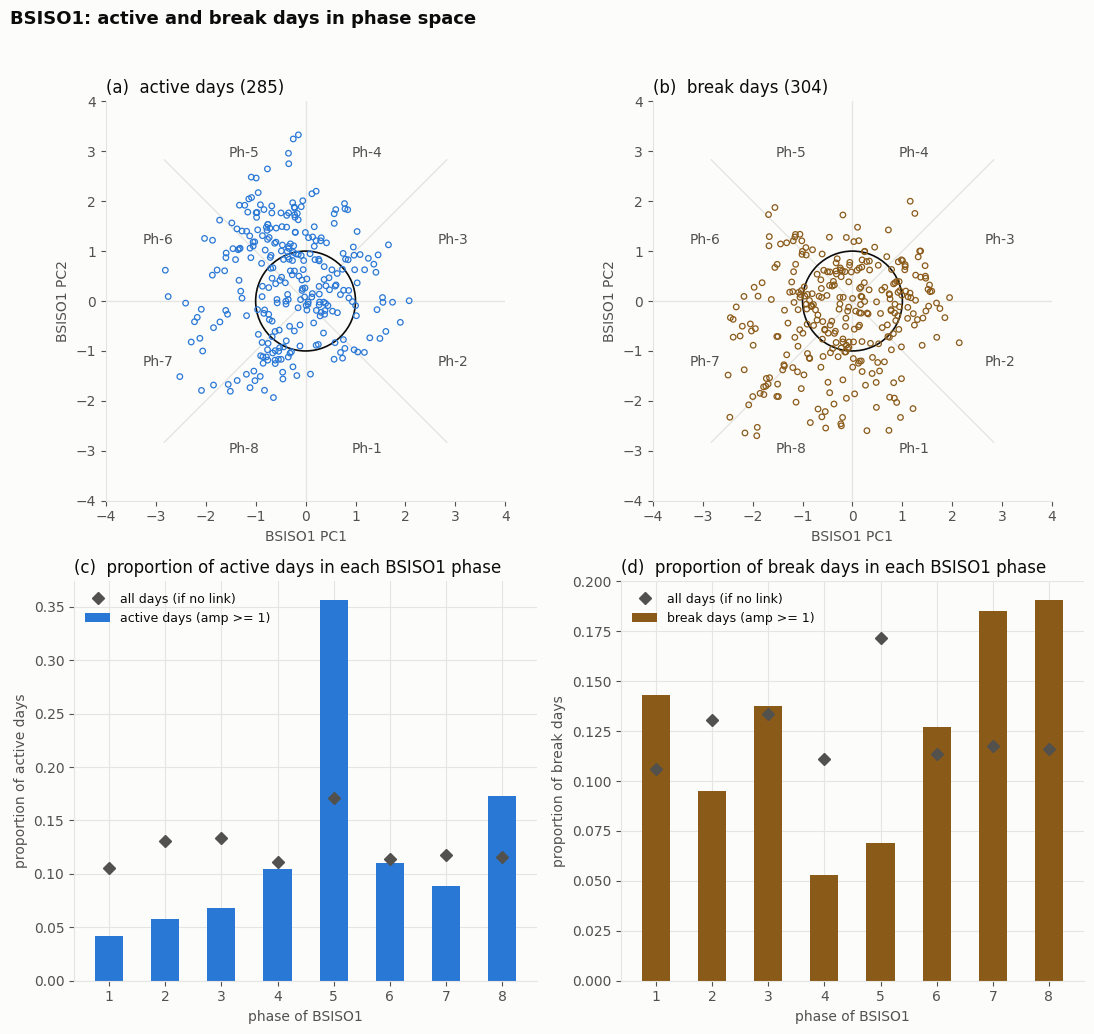

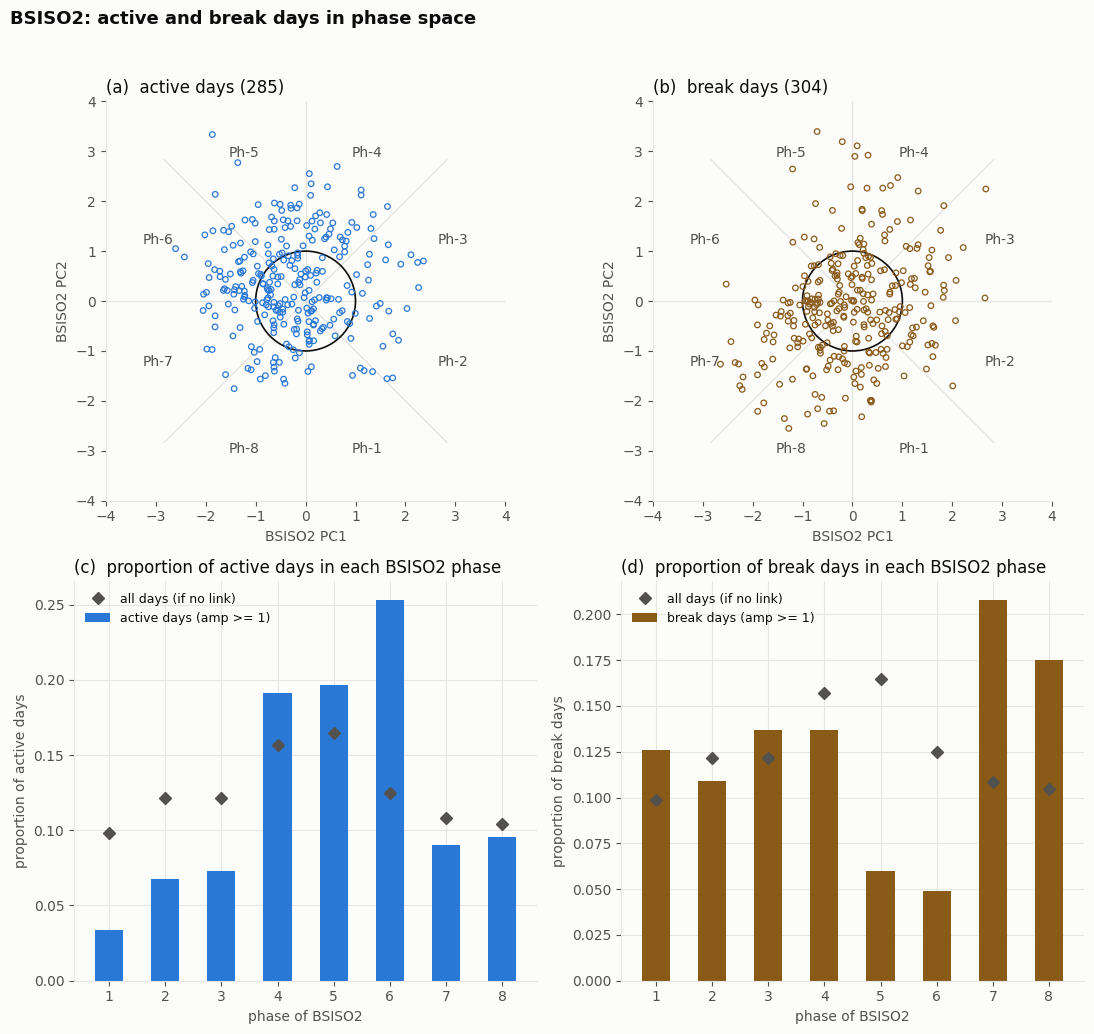

In [10]:
R = 4.0
to_xy = lambda th, r: (r * np.sin(np.deg2rad(th)), -r * np.cos(np.deg2rad(th)))


def phase_frame(a, label="Ph-", rmax=R, fs=10):
    for k in range(8):
        a.plot(*zip((0, 0), to_xy(k * 45, rmax)), color=GRID, lw=1, zorder=1)
    a.add_patch(plt.Circle((0, 0), 1, fill=False, ec=INK, lw=1.2, zorder=2))
    for k in range(1, 9):
        a.text(*to_xy((k - 0.5) * 45, rmax * 0.8), f"{label}{k}", ha="center", va="center", fontsize=fs, color=INK2)
    a.set(xlim=(-rmax, rmax), ylim=(-rmax, rmax), aspect="equal")
    a.grid(False)


def fig_phase_scatter(mode):
    M = MODES[mode]
    fig, ax = plt.subplots(2, 2, figsize=(11, 10.5))
    x8 = np.arange(1, 9)
    strong = M["amp"] >= 1
    share_all = np.array([(M["phase"][strong] == k).mean() for k in x8])
    for j, (v, col, nm) in enumerate(((1, BLUE, "active"), (-1, BROWN, "break"))):
        sel = lab == v
        a = ax[0, j]
        phase_frame(a)
        a.scatter(M["pc1"][sel], M["pc2"][sel], s=16, facecolor="none", edgecolor=col, lw=0.9, zorder=3)
        a.set(xlabel=f"{mode} PC1", ylabel=f"{mode} PC2")
        a.set_title(f"({'ab'[j]})  {nm} days ({sel.sum()})", loc="left")
        a = ax[1, j]
        sh = np.array([(M["phase"][sel & strong] == k).mean() for k in x8])
        a.bar(x8, sh, color=col, width=0.5, label=f"{nm} days (amp >= 1)")
        a.plot(x8, share_all, "D", color=INK2, ms=6, label="all days (if no link)")
        a.set(xticks=x8, xlabel=f"phase of {mode}", ylabel=f"proportion of {nm} days")
        a.set_title(f"({'cd'[j]})  proportion of {nm} days in each {mode} phase", loc="left")
        a.legend(frameon=False, fontsize=9)
    fig.suptitle(f"{mode}: active and break days in phase space", x=0.01, ha="left", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.savefig(os.path.join(OUT, f"fig1_scatter_{mode}.png"), dpi=140, bbox_inches="tight")
    plt.show()


for mode in ("BSISO1", "BSISO2"):
    fig_phase_scatter(mode)

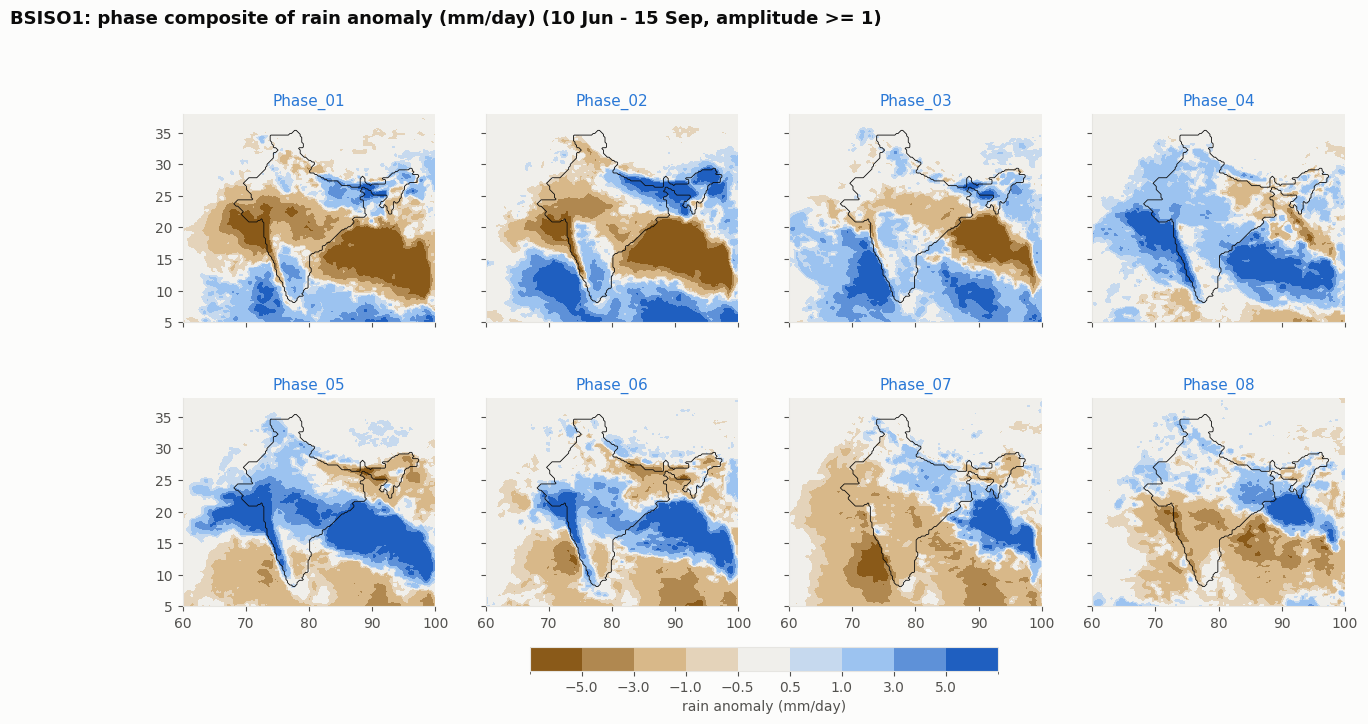

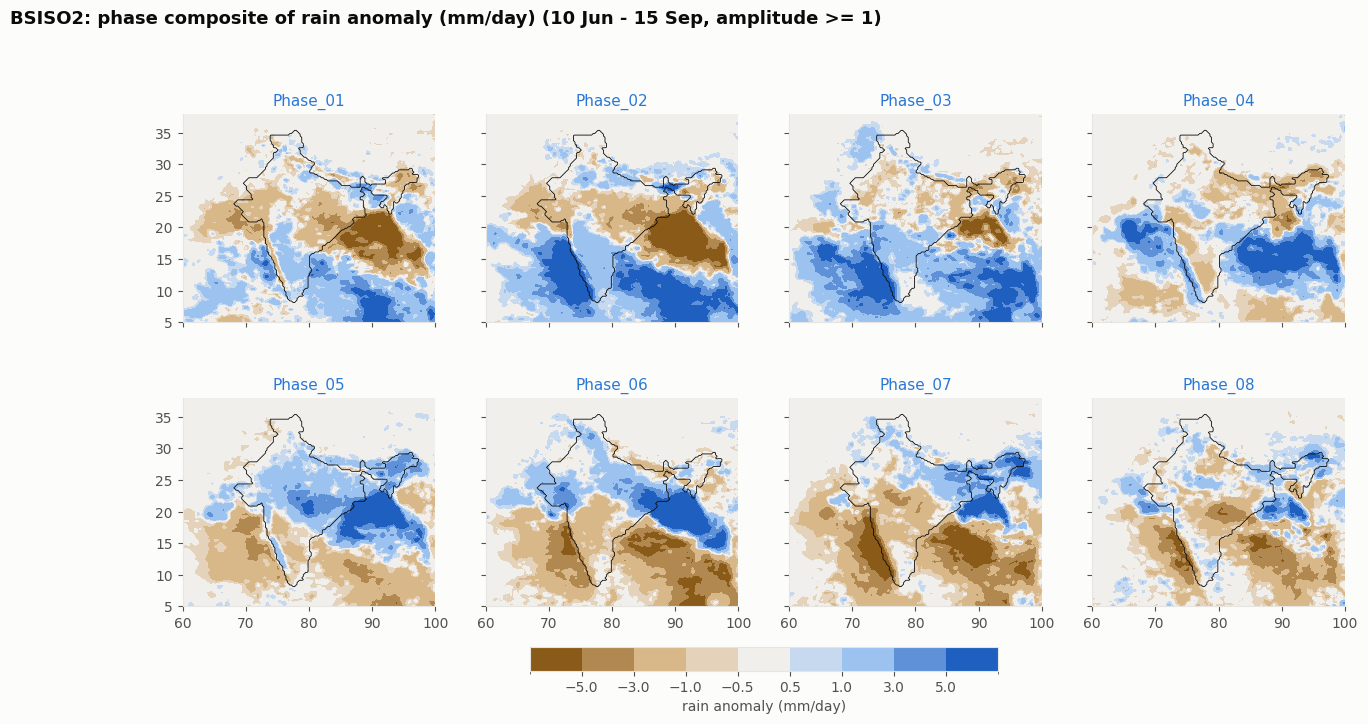

In [11]:
def anomalies(field):
    """Daily anomaly from a 15-day-smoothed calendar-day climatology (works for any (time, ...) field)."""
    cm = np.stack([np.nanmean(field[kidx == k], axis=0) for k in range(ND)])
    shp = cm.shape
    cm = pd.DataFrame(cm.reshape(ND, -1)).rolling(15, center=True, min_periods=1).mean().values.reshape(shp)
    return (field - cm[kidx]).astype("float32")


anom = anomalies(tp)
COMP_WINDOW = (keys >= "0610") & (keys <= "0915")     # the paper uses 10 June - 15 September
LEVELS = [-5, -3, -1, -0.5, 0.5, 1, 3, 5]


def composites(field, mode):
    M = MODES[mode]
    return np.stack([np.nanmean(field[COMP_WINDOW & (M["amp"] >= 1) & (M["phase"] == k)], axis=0)
                     for k in range(1, 9)])


def fig_maps(comp, mode, what="rain anomaly (mm/day)", name="fig3", levels=LEVELS, cmap=RAIN_CM, la=lat, lo=lon,
             extent=(60, 100, 5, 38), outline=True):
    fig, ax = plt.subplots(2, 4, figsize=(15, 7.6))
    norm = BoundaryNorm([-99] + levels + [99], cmap.N, extend="neither")
    for k in range(8):
        a = ax[k // 4, k % 4]
        im = a.contourf(lo, la, comp[k], levels=[-99] + levels + [99], cmap=cmap, norm=norm)
        if outline:
            a.contour(lon, lat, mask.astype(float), levels=[0.5], colors=INK, linewidths=0.6)
        a.set(xlim=extent[:2], ylim=extent[2:], aspect="equal")
        a.grid(False)
        a.set_title(f"Phase_{k + 1:02d}", fontsize=11, color=BLUE)
        if k % 4: a.set_yticklabels([])
        if k < 4: a.set_xticklabels([])
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.04, pad=0.07, ticks=levels)
    cb.set_label(what, color=INK2)
    fig.suptitle(f"{mode}: phase composite of {what} (10 Jun - 15 Sep, amplitude >= 1)", x=0.01, ha="left",
                 fontsize=13, fontweight="bold")
    plt.savefig(os.path.join(OUT, f"{name}_{mode}.png"), dpi=140, bbox_inches="tight")
    plt.show()


COMP = {mode: composites(anom, mode) for mode in ("BSISO1", "BSISO2")}
for mode in ("BSISO1", "BSISO2"):
    fig_maps(COMP[mode], mode)

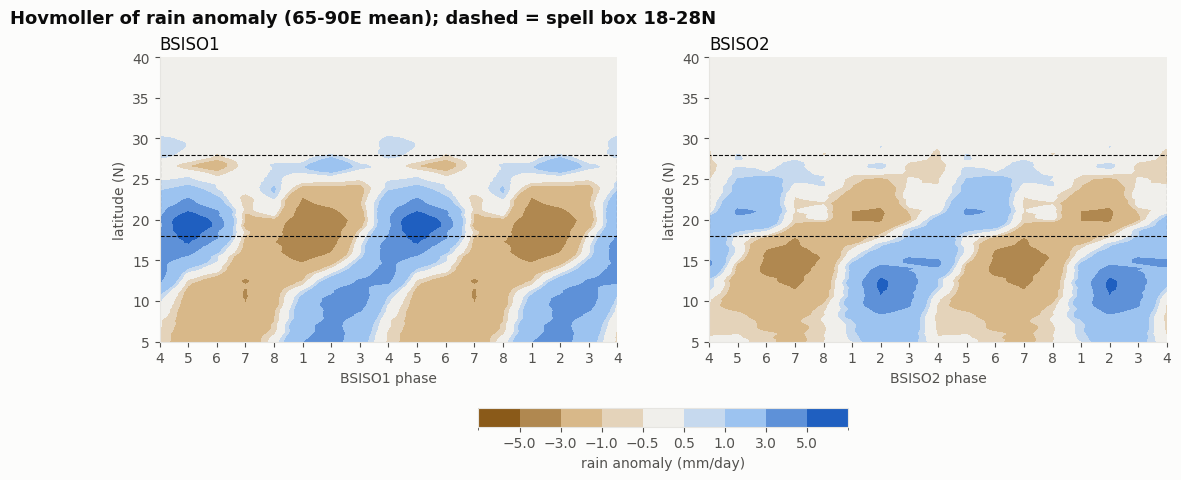

In [12]:
REP = [4, 5, 6, 7, 8, 1, 2, 3, 4, 5, 6, 7, 8, 1, 2, 3, 4]


def hov(comp, lo_=lon, lon_range=(65, 90)):
    sel = (lo_ >= lon_range[0]) & (lo_ <= lon_range[1])
    h = np.nanmean(comp[:, :, sel], axis=2)          # (8, lat)
    return np.stack([h[p - 1] for p in REP])         # (17, lat)


def fig_hov(H, la, title, name, levels=LEVELS, cmap=RAIN_CM, label="rain anomaly (mm/day)", ylim=(5, 40)):
    fig, ax = plt.subplots(1, len(H), figsize=(6.5 * len(H), 4.8))
    ax = np.atleast_1d(ax)
    for a, (mode, h) in zip(ax, H.items()):
        norm = BoundaryNorm([-99] + levels + [99], cmap.N)
        im = a.contourf(np.arange(len(REP)), la, h.T, levels=[-99] + levels + [99], cmap=cmap, norm=norm)
        a.set_xticks(np.arange(len(REP)), [str(p) for p in REP])
        a.set(ylim=ylim, xlabel=f"{mode} phase", ylabel="latitude (N)")
        a.axhspan(18, 28, color="none", ec=INK, lw=0.8, ls="--")
        a.grid(False)
        a.set_title(f"{mode}", loc="left")
    fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.18, ticks=levels).set_label(label, color=INK2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    plt.savefig(os.path.join(OUT, f"{name}.png"), dpi=140, bbox_inches="tight")
    plt.show()


fig_hov({m: hov(COMP[m]) for m in ("BSISO1", "BSISO2")}, lat,
        "Hovmoller of rain anomaly (65-90E mean); dashed = spell box 18-28N", "fig4_hovmoller_rain")

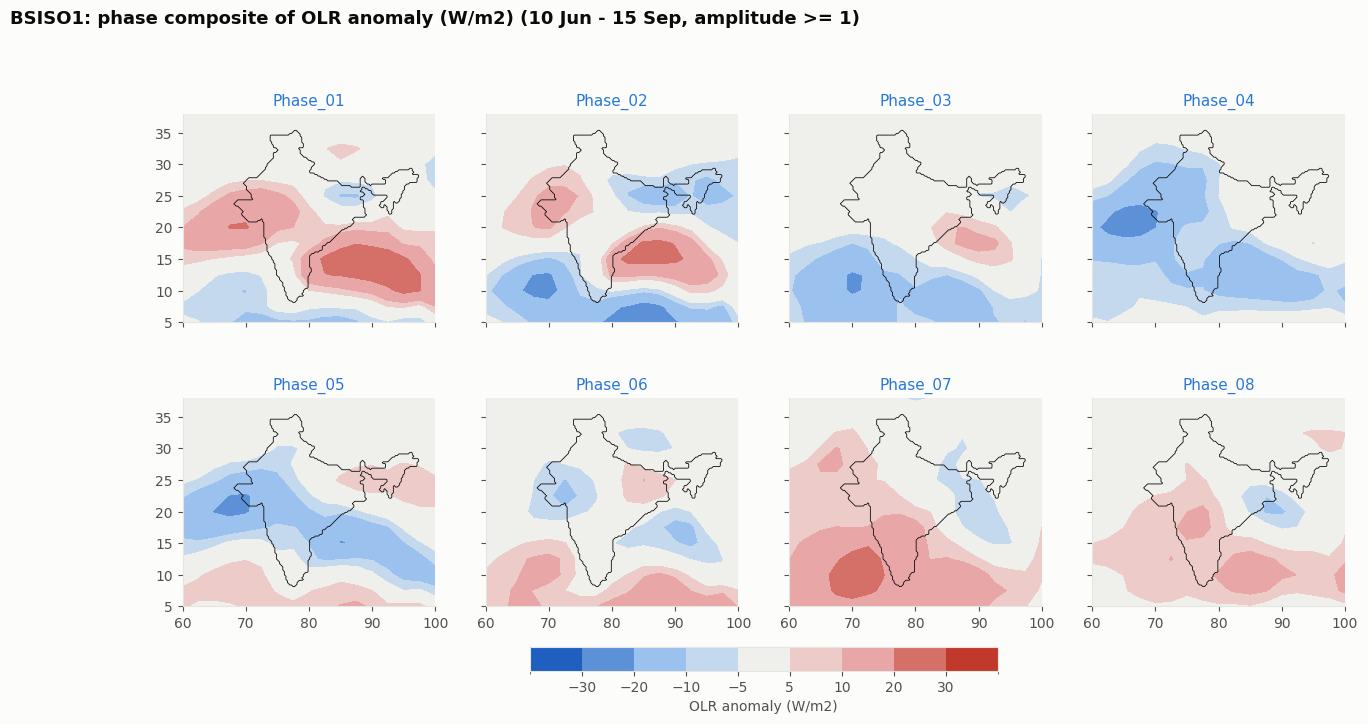

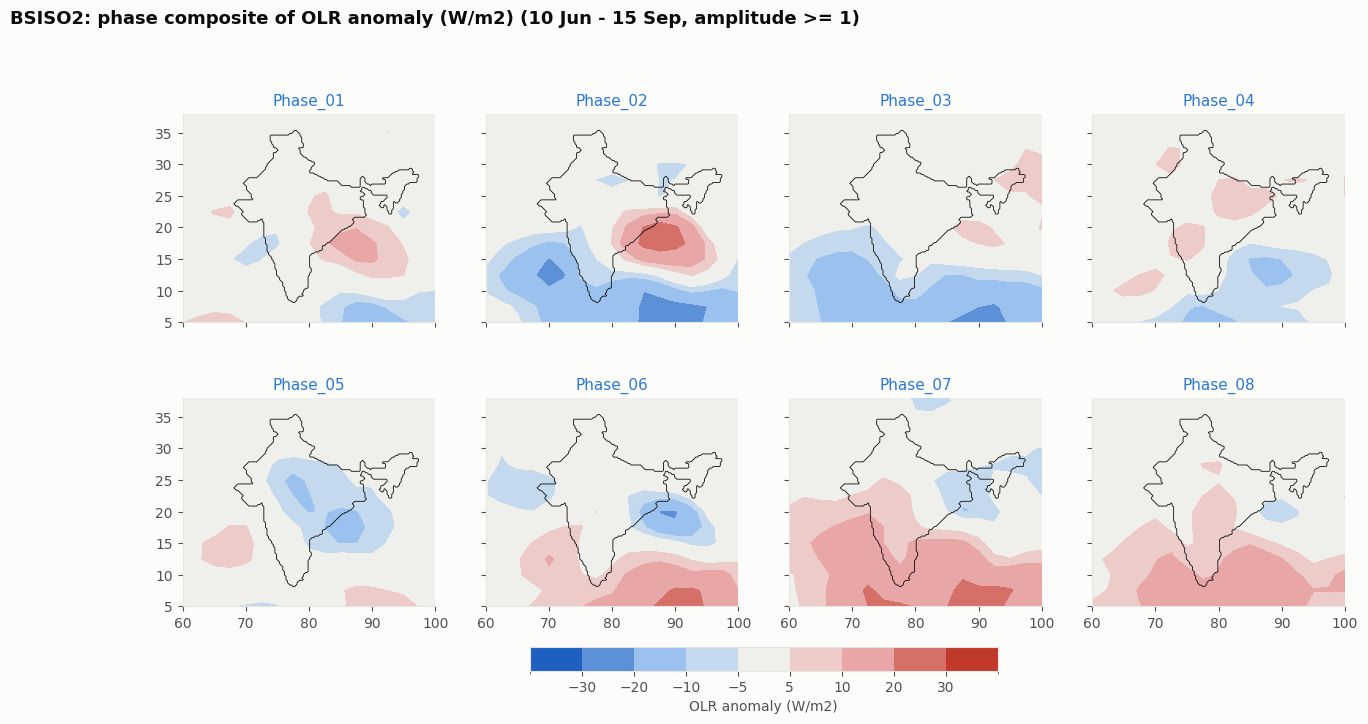

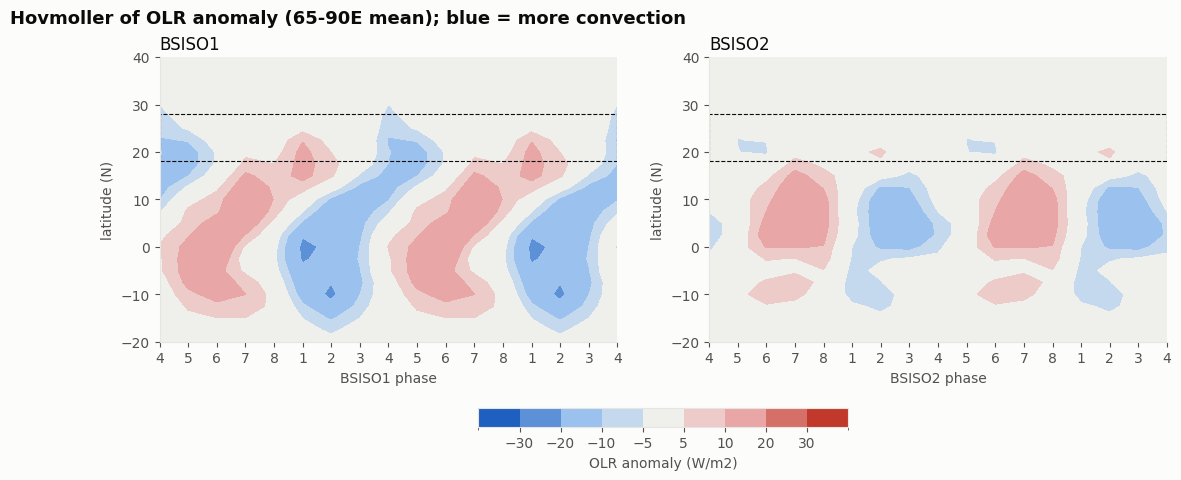

In [13]:
if olr_path is None:
    print("OLR subset not attached: skipped")
else:
    ds = xr.open_dataset(olr_path)
    olr = ds["olr"].sel(time=times).values.astype("float32")      # same JJAS days as IMERG
    olat, olon = ds["lat"].values, ds["lon"].values
    ds.close()
    oanom = anomalies(olr)
    OLR_LEV = [-30, -20, -10, -5, 5, 10, 20, 30]
    OCOMP = {m: composites(oanom, m) for m in ("BSISO1", "BSISO2")}
    for m in ("BSISO1", "BSISO2"):
        fig_maps(OCOMP[m], m, what="OLR anomaly (W/m2)", name="fig5_olr", levels=OLR_LEV, cmap=OLR_CM,
                 la=olat, lo=olon, extent=(60, 100, 5, 38))
    fig_hov({m: hov(OCOMP[m], lo_=olon) for m in ("BSISO1", "BSISO2")}, olat,
            "Hovmoller of OLR anomaly (65-90E mean); blue = more convection", "fig6_hovmoller_olr",
            levels=OLR_LEV, cmap=OLR_CM, label="OLR anomaly (W/m2)", ylim=(-20, 40))

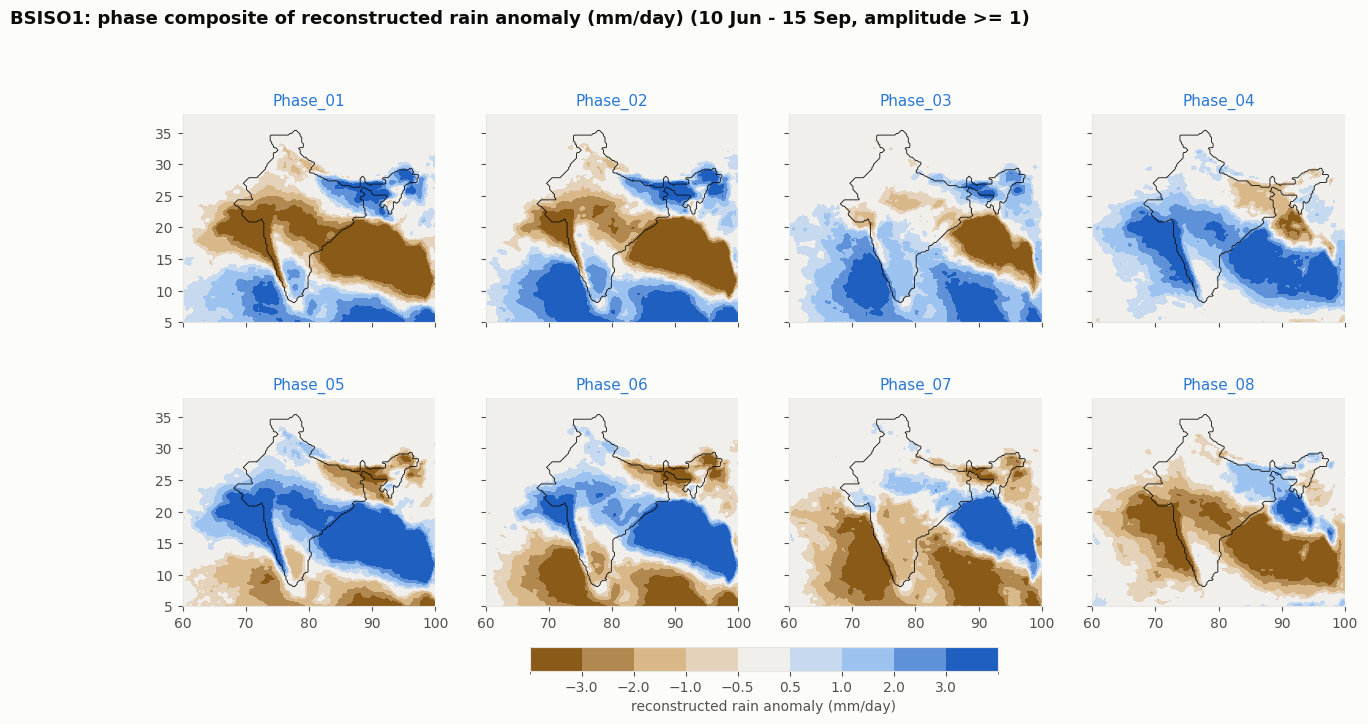

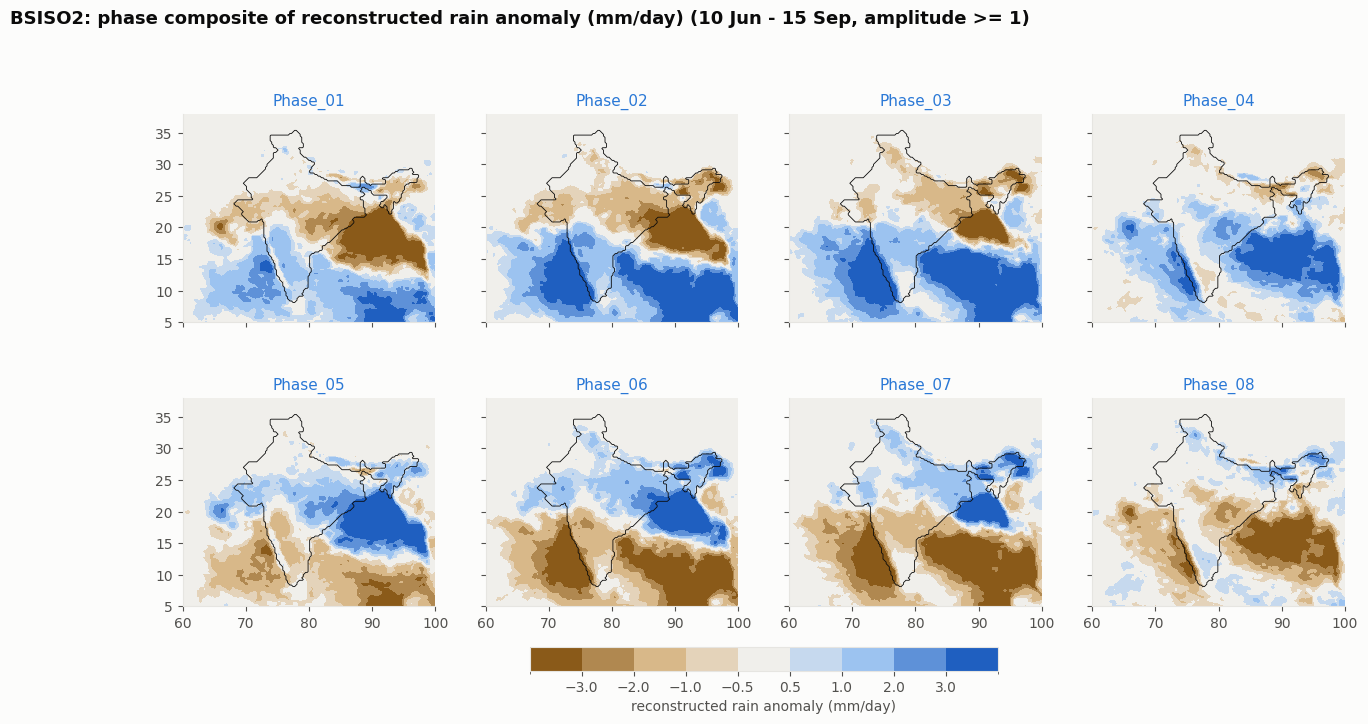

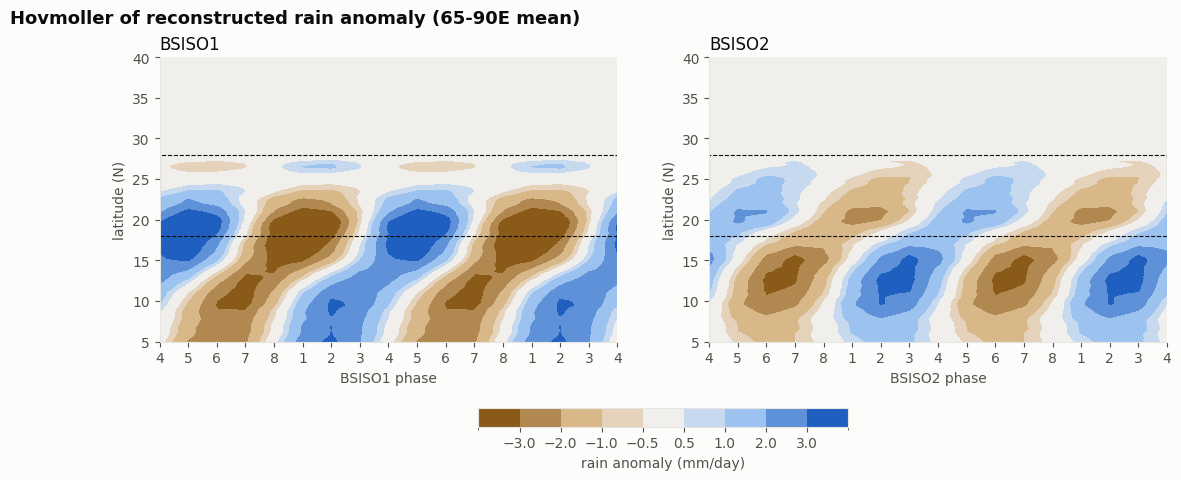

In [14]:
A2 = anom.reshape(len(times), -1)
RECON = {}
for mode in ("BSISO1", "BSISO2"):
    M = MODES[mode]
    G = np.column_stack([np.ones(len(times)), M["pc1"], M["pc2"]])
    coef, *_ = np.linalg.lstsq(G, np.nan_to_num(A2), rcond=None)
    RECON[mode] = (G @ coef).astype("float32").reshape(anom.shape)
RCOMP = {m: composites(RECON[m], m) for m in ("BSISO1", "BSISO2")}
for mode in ("BSISO1", "BSISO2"):
    fig_maps(RCOMP[mode], mode, what="reconstructed rain anomaly (mm/day)", name="fig7_recon",
             levels=[-3, -2, -1, -0.5, 0.5, 1, 2, 3])
fig_hov({m: hov(RCOMP[m]) for m in ("BSISO1", "BSISO2")}, lat,
        "Hovmoller of reconstructed rain anomaly (65-90E mean)", "fig8_hovmoller_recon",
        levels=[-3, -2, -1, -0.5, 0.5, 1, 2, 3])

active: 18 spells of >= 5 days


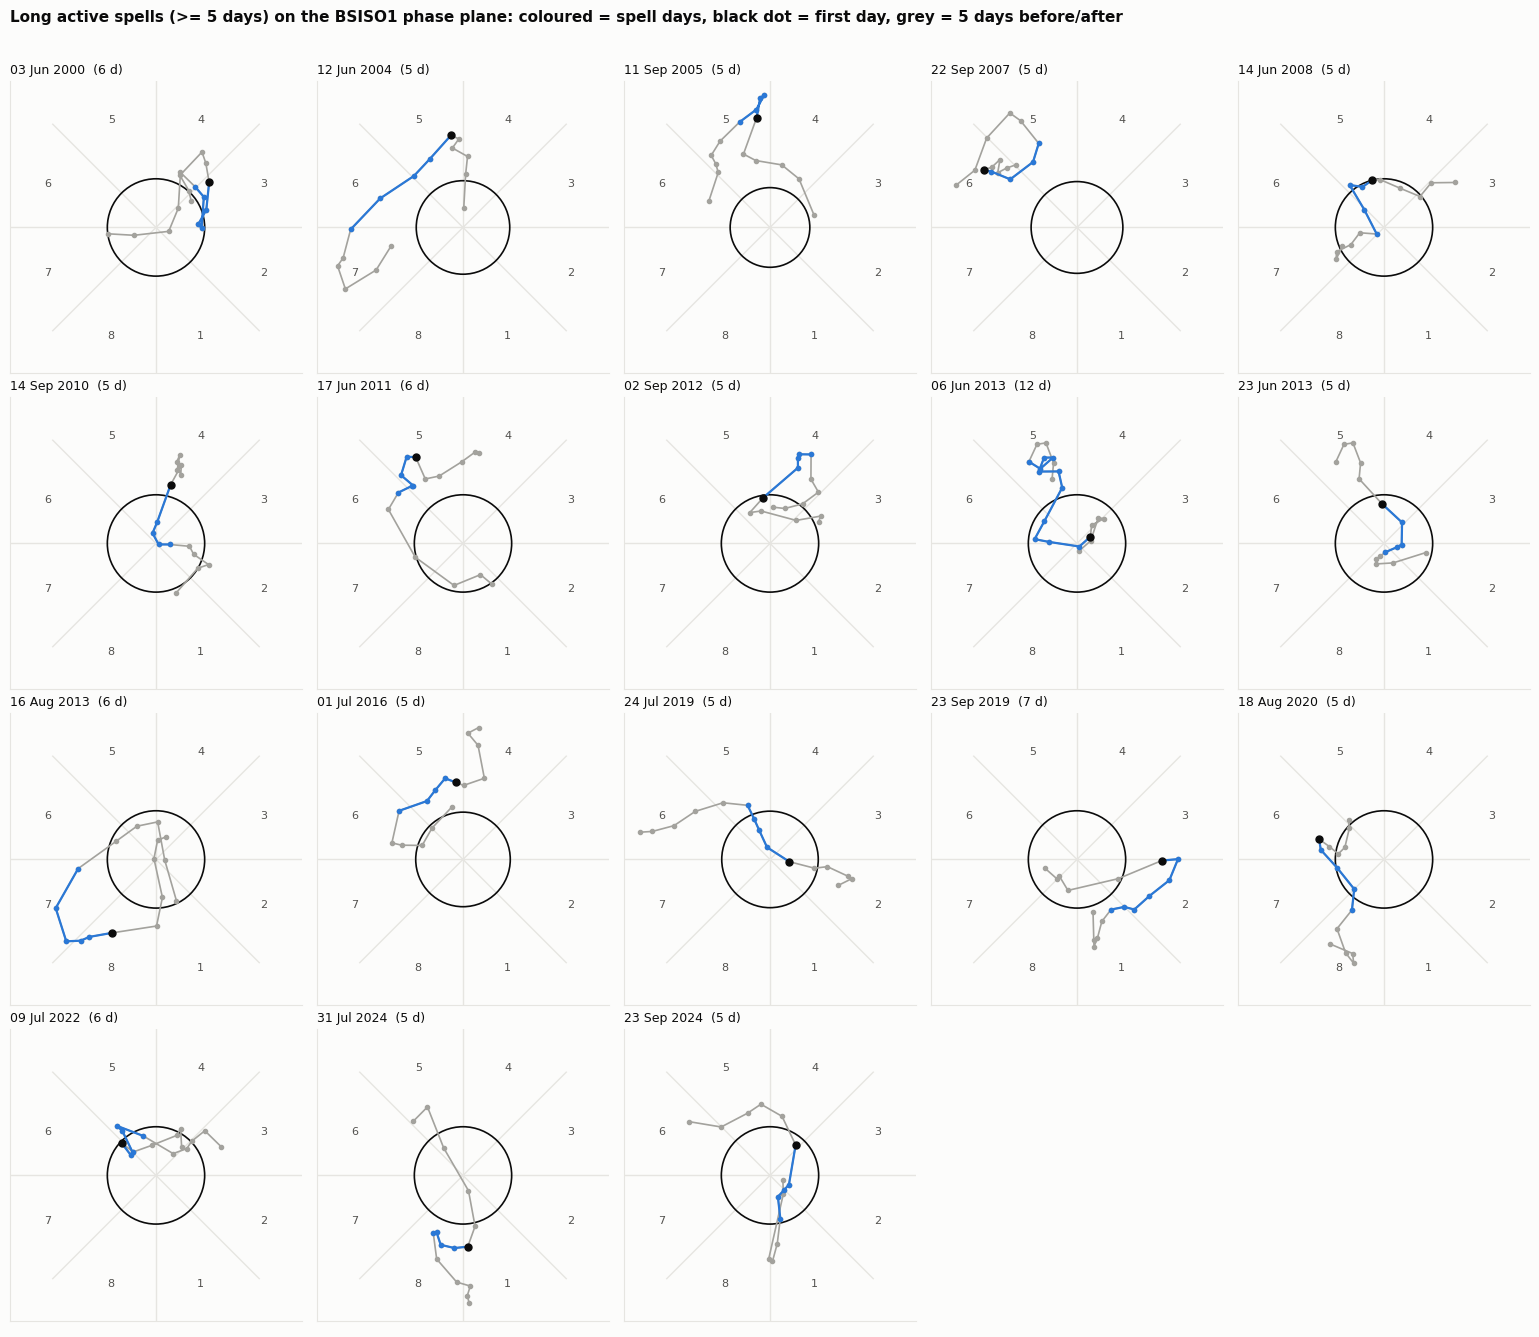

break: 28 spells of >= 5 days


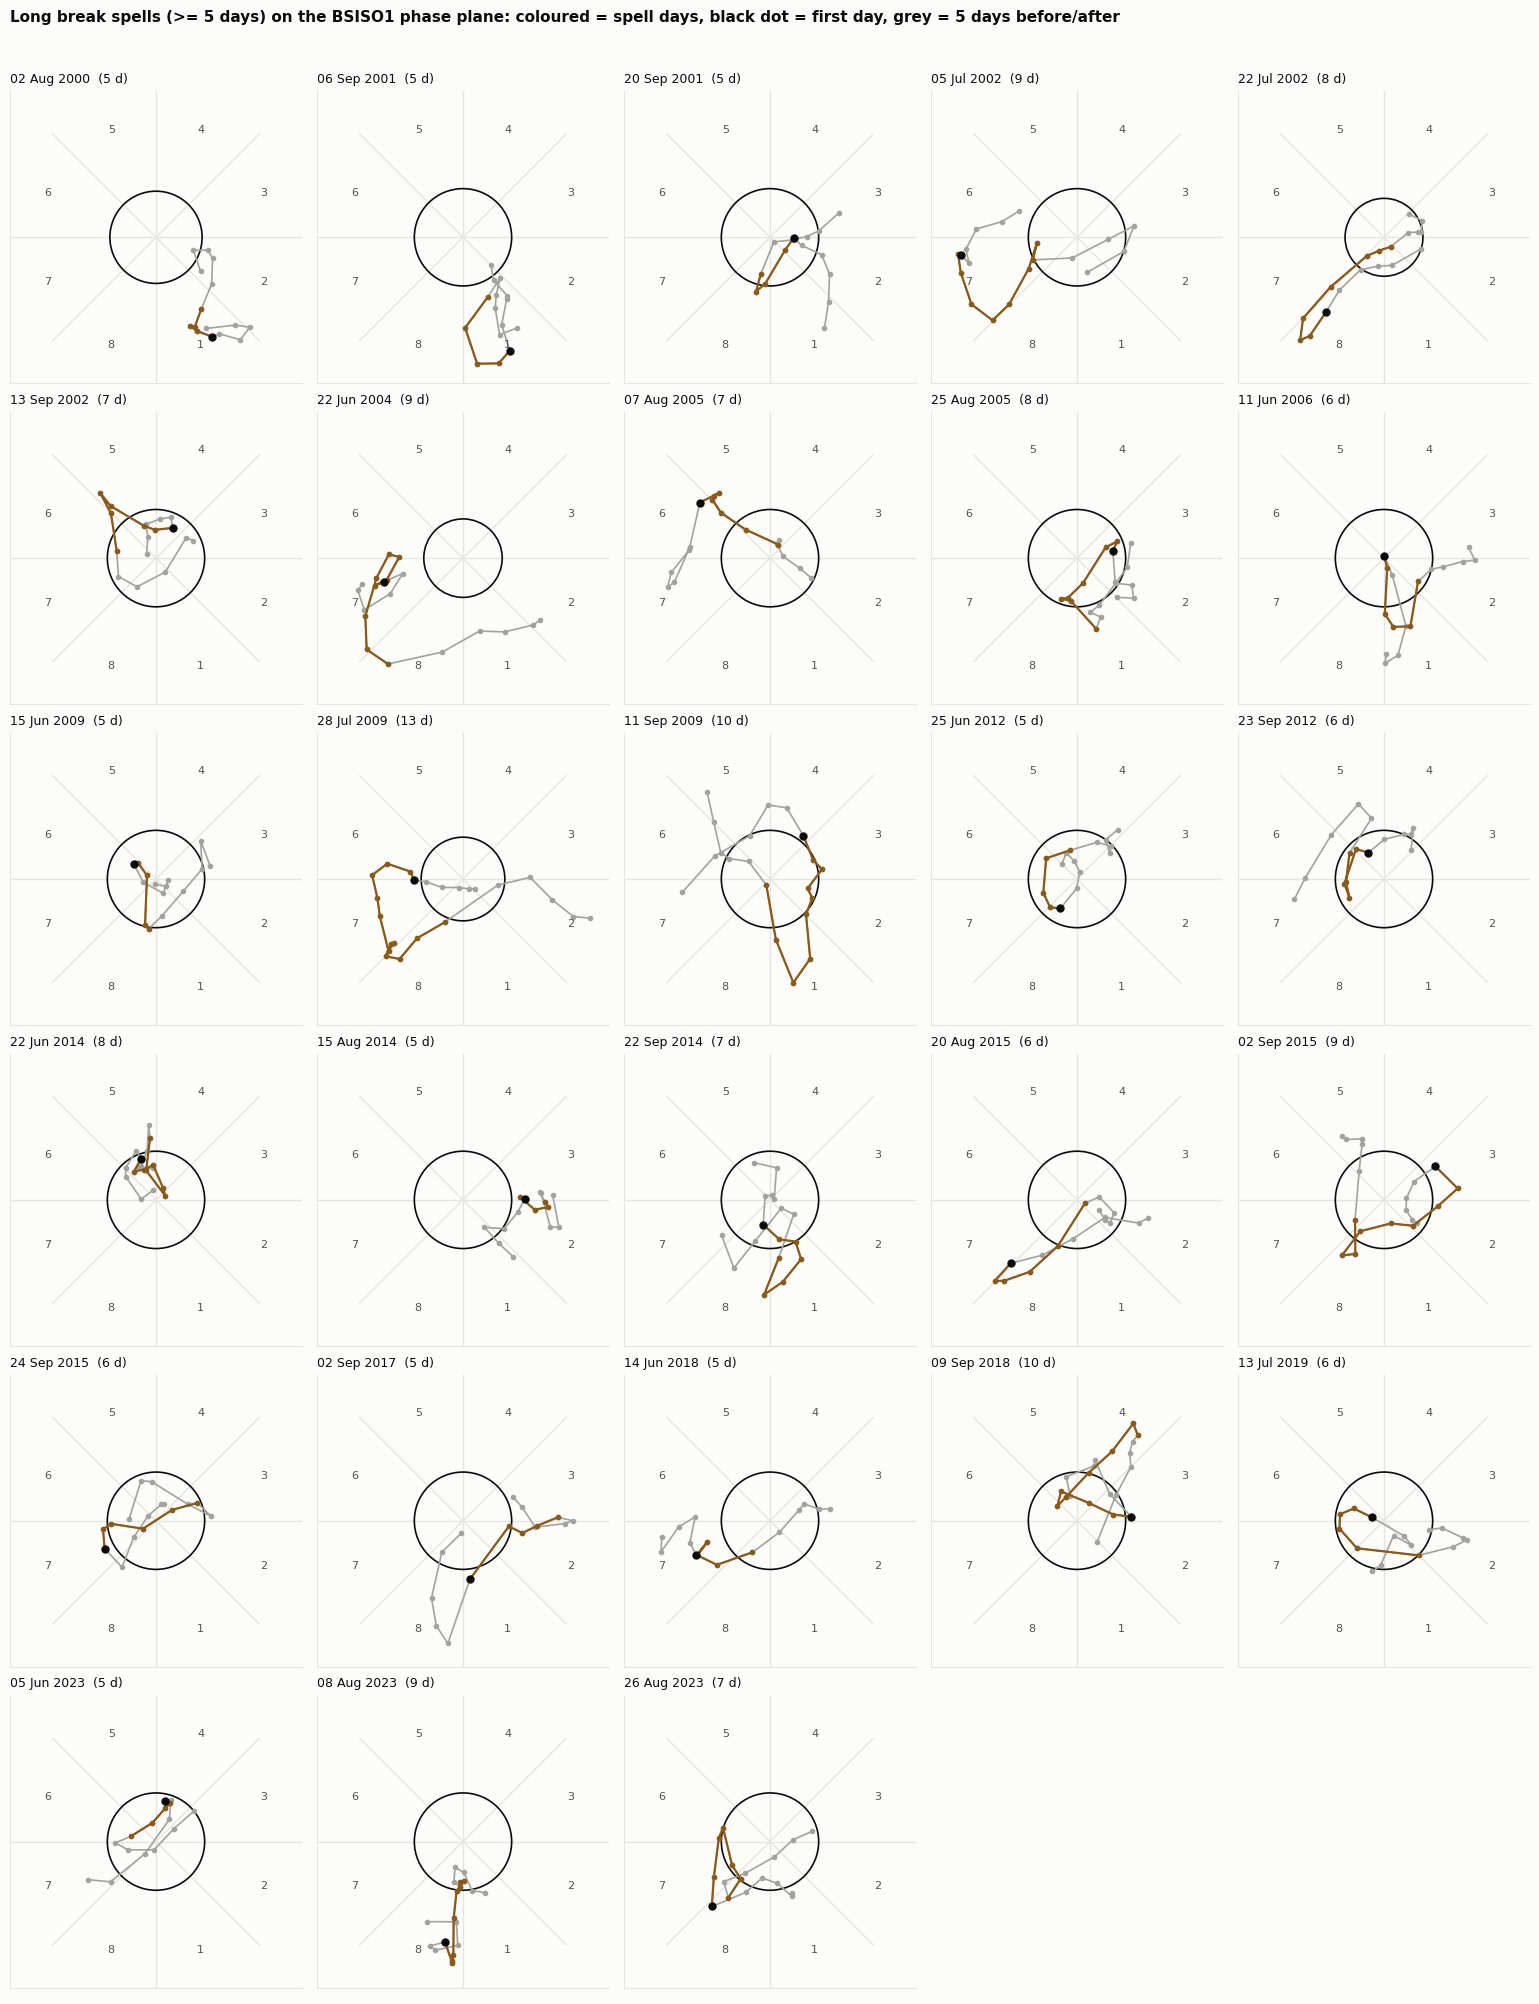

In [15]:
LONG_MIN = 5                                   # paper uses >= 7 days; IMERG 2000-2024 has very few such ACTIVE spells
PAD = 5                                        # days shown before and after each spell (grey)


def fig_tracks(runs, kind, col):
    longs = [(i, j) for i, j in runs if j - i + 1 >= LONG_MIN]
    n = len(longs)
    print(f"{kind}: {n} spells of >= {LONG_MIN} days")
    if n == 0:
        return
    per_row = 5
    rows_ = int(np.ceil(n / per_row))
    fig, ax = plt.subplots(rows_, per_row, figsize=(per_row * 3.1, rows_ * 3.4))
    ax = np.atleast_2d(ax)
    for a in ax.ravel():
        a.axis("off")
    P1, P2 = MODES["BSISO1"]["PC1"], MODES["BSISO1"]["PC2"]
    for s, (i, j) in enumerate(longs):
        a = ax[s // per_row, s % per_row]
        a.axis("on")
        d0, d1 = times[i] - pd.Timedelta(days=PAD), times[j] + pd.Timedelta(days=PAD)
        rmax = max(3, 1.1 * np.nanmax(np.hypot(P1[d0:d1].values, P2[d0:d1].values)))   # widen if the track is large
        phase_frame(a, label="", rmax=rmax, fs=8)
        a.plot(P1[d0:d1].values, P2[d0:d1].values, "o-", color="#a3a29d", lw=1.2, ms=3, zorder=2)   # one dot per day
        a.plot(P1[times[i]:times[j]].values, P2[times[i]:times[j]].values, "o-", color=col, lw=1.6, ms=3, zorder=3)
        a.plot(P1[times[i]], P2[times[i]], "o", color=INK, ms=5, zorder=4)
        a.set_xticks([]); a.set_yticks([])
        a.set_title(f"{times[i]:%d %b %Y}  ({j - i + 1} d)", fontsize=9, loc="left")
    fig.suptitle(f"Long {kind} spells (>= {LONG_MIN} days) on the BSISO1 phase plane: coloured = spell days, "
                 f"black dot = first day, grey = {PAD} days before/after", x=0.01, ha="left", fontsize=11,
                 fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.savefig(os.path.join(OUT, f"fig10_11_tracks_{kind}.png"), dpi=130, bbox_inches="tight")
    plt.show()


fig_tracks(act_runs, "active", BLUE)
fig_tracks(brk_runs, "break", BROWN)

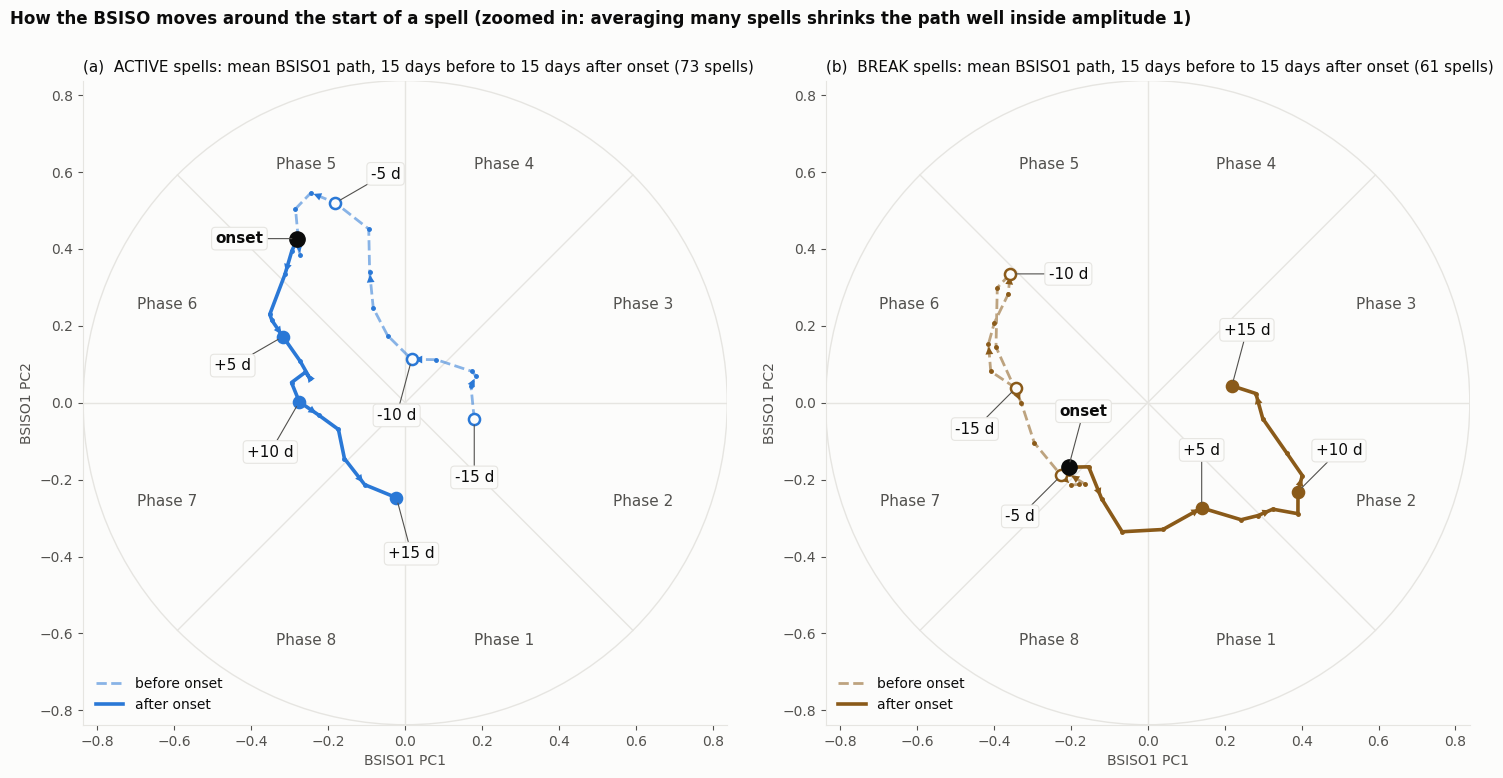

In [16]:
LAGS = np.arange(-15, 16)
KEY = (-15, -10, -5, 0, 5, 10, 15)
P1, P2 = MODES["BSISO1"]["PC1"], MODES["BSISO1"]["PC2"]


def mean_path(runs):
    onsets = [times[i] for i, _ in runs]
    mp = np.array([[P1.get(t + pd.Timedelta(days=int(L)), np.nan) for t in onsets] for L in LAGS])
    mq = np.array([[P2.get(t + pd.Timedelta(days=int(L)), np.nan) for t in onsets] for L in LAGS])
    return np.nanmean(mp, axis=1), np.nanmean(mq, axis=1), len(onsets)


def place_labels(a, x_, y_, rmax):
    """Put each key-day label where it is farthest from the path and from the other labels."""
    t = np.linspace(0, len(x_) - 1, 400)
    dense = np.column_stack([np.interp(t, np.arange(len(x_)), x_), np.interp(t, np.arange(len(y_)), y_)])
    taken = [np.array(to_xy((k - 0.5) * 45, 0.8 * rmax)) for k in range(1, 9)]   # keep clear of phase names
    for L in sorted(KEY, key=lambda v: (v != 0, abs(v))):          # onset first, then outwards
        k = int(np.where(LAGS == L)[0][0])
        best, best_sc = None, -1
        for d in (0.10, 0.14, 0.18):
            for ang in np.linspace(0, 2 * np.pi, 24, endpoint=False):
                c = np.array([x_[k] + d * rmax * np.cos(ang), y_[k] + d * rmax * np.sin(ang)])
                if np.abs(c).max() > 0.9 * rmax:
                    continue
                sc = np.hypot(*(dense - c).T).min()
                if taken:
                    sc = min(sc, 0.6 * np.hypot(*(np.array(taken) - c).T).min())
                sc -= 0.02 * d * rmax                                    # prefer labels close to their point
                if sc > best_sc:
                    best, best_sc = c, sc
        taken.append(best)
        a.annotate("onset" if L == 0 else f"{L:+d} d", (x_[k], y_[k]), xytext=best, textcoords="data",
                   ha="center", va="center", fontsize=11, fontweight="bold" if L == 0 else None, zorder=6,
                   bbox=dict(boxstyle="round,pad=0.25", fc=SURF, ec=GRID, lw=0.8),
                   arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8, shrinkA=0, shrinkB=4))


PATHS = {kind: mean_path(runs) for runs, kind in ((act_runs, "active"), (brk_runs, "break"))}
rmax = max(0.6, 1.4 * max(np.nanmax(np.hypot(x_, y_)) for x_, y_, _ in PATHS.values()))

fig, ax = plt.subplots(1, 2, figsize=(15, 7.6))
for a, (kind, col), tag in zip(ax, (("active", BLUE), ("break", BROWN)), "ab"):
    x_, y_, n_sp = PATHS[kind]
    phase_frame(a, label="Phase ", rmax=rmax, fs=11)
    for p_ in list(a.patches):                                           # drop the amplitude-1 circle (off-scale)
        p_.remove()
    a.add_patch(plt.Circle((0, 0), rmax, fill=False, ec=GRID, lw=1))
    pre, post = LAGS <= 0, LAGS >= 0
    a.plot(x_[pre], y_[pre], "--", color=col, lw=2, alpha=0.55, zorder=3, label="before onset")
    a.plot(x_[post], y_[post], "-", color=col, lw=2.6, zorder=3, label="after onset")
    a.plot(x_, y_, "o", color=col, ms=2.5, zorder=3)                     # one small dot per day
    for k in range(1, len(LAGS) - 1, 3):                                 # arrows show the direction of travel
        a.annotate("", (x_[k + 1], y_[k + 1]), (x_[k], y_[k]), zorder=4,
                   arrowprops=dict(arrowstyle="-|>", color=col, lw=0, mutation_scale=14))
    for L in KEY:
        k = int(np.where(LAGS == L)[0][0])
        if L == 0:
            a.plot(x_[k], y_[k], "o", color=INK, ms=11, zorder=5)
        else:
            a.plot(x_[k], y_[k], "o", ms=8, zorder=5, mec=col, mew=1.8, mfc=SURF if L < 0 else col)
    place_labels(a, x_, y_, rmax)
    a.set(xlabel="BSISO1 PC1", ylabel="BSISO1 PC2")
    a.set_title(f"({tag})  {kind.upper()} spells: mean BSISO1 path, 15 days before to 15 days after onset "
                f"({n_sp} spells)", loc="left", fontsize=11)
    a.legend(frameon=False, fontsize=10, loc="lower left")
fig.suptitle("How the BSISO moves around the start of a spell (zoomed in: averaging many spells "
             "shrinks the path well inside amplitude 1)", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(os.path.join(OUT, "fig12_onset_bsiso_path.png"), dpi=140, bbox_inches="tight")
plt.show()

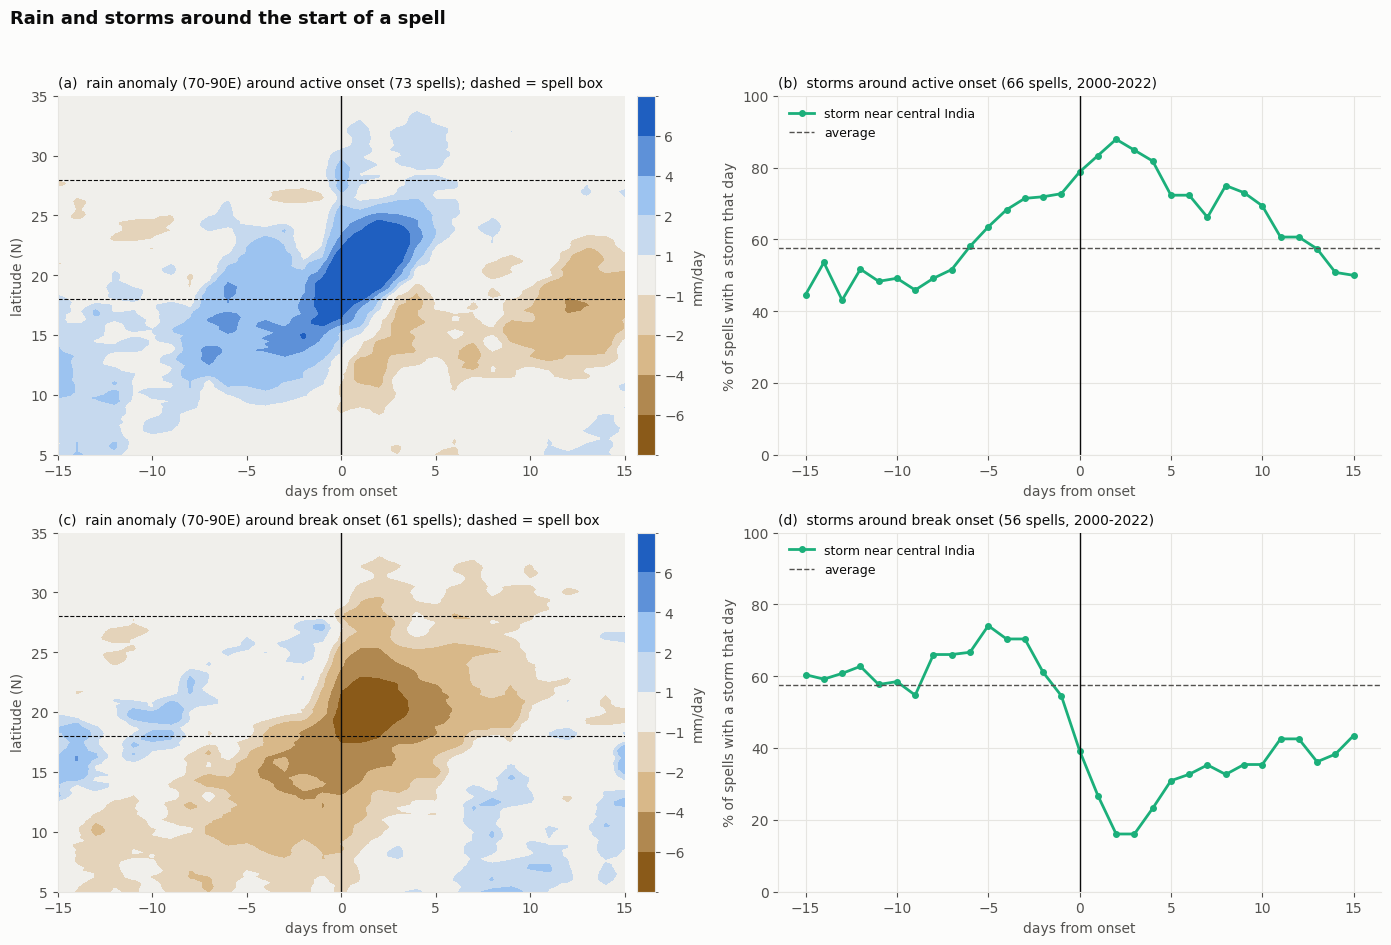

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9.6))
tix = pd.Series(np.arange(len(times)), index=times)
sel_lon = (lon >= 70) & (lon <= 90)
lv = [-6, -4, -2, -1, 1, 2, 4, 6]
base = storm_near[years <= 2022].mean()
for r_, (runs, kind) in enumerate(((act_runs, "active"), (brk_runs, "break"))):
    onsets = [times[i] for i, _ in runs]
    # rain anomaly vs latitude and lag (70-90E)
    hl = np.full((len(LAGS), len(lat)), np.nan)
    for k, L in enumerate(LAGS):
        idx = [tix.get(t + pd.Timedelta(days=int(L))) for t in onsets]
        idx = [i for i in idx if i is not None and not np.isnan(i)]
        if idx:
            hl[k] = np.nanmean(anom[np.array(idx, int)][:, :, sel_lon], axis=(0, 2))
    a = ax[r_, 0]
    im = a.contourf(LAGS, lat, hl.T, levels=[-99] + lv + [99], cmap=RAIN_CM,
                    norm=BoundaryNorm([-99] + lv + [99], RAIN_CM.N))
    a.axhline(18, color=INK, lw=0.8, ls="--"); a.axhline(28, color=INK, lw=0.8, ls="--"); a.axvline(0, color=INK, lw=1)
    a.set(xlabel="days from onset", ylabel="latitude (N)", ylim=(5, 35))
    a.grid(False)
    a.set_title(f"({'ac'[r_]})  rain anomaly (70-90E) around {kind} onset ({len(onsets)} spells); "
                f"dashed = spell box", loc="left", fontsize=10)
    fig.colorbar(im, ax=a, fraction=0.04, pad=0.02, ticks=lv).set_label("mm/day", color=INK2)
    # storm presence around onset
    a = ax[r_, 1]
    on22 = [t for t in onsets if t.year <= 2022]
    sf = [np.nanmean([storm_near[tix[t + pd.Timedelta(days=int(L))]] for t in on22
                      if (t + pd.Timedelta(days=int(L))) in tix.index]) for L in LAGS]
    a.plot(LAGS, 100 * np.array(sf), "o-", color=GREEN, lw=2, ms=4, label="storm near central India")
    a.axhline(100 * base, color=INK2, ls="--", lw=1, label="average")
    a.axvline(0, color=INK, lw=1)
    a.set(xlabel="days from onset", ylabel="% of spells with a storm that day", ylim=(0, 100))
    a.set_title(f"({'bd'[r_]})  storms around {kind} onset ({len(on22)} spells, 2000-2022)", loc="left", fontsize=10)
    a.legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Rain and storms around the start of a spell", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(os.path.join(OUT, "fig13_onset_rain_storms.png"), dpi=140, bbox_inches="tight")
plt.show()

EXTREME RAINFALL TRACKS AND BSISO

ERE rate in each BSISO1 phase (amplitude >= 1) relative to the average day; 1.00 = average


,events,ph1,ph2,ph3,ph4,ph5,ph6,ph7,ph8,pattern p
series,,,,,,,,,,
All India,10877,0.97,1.14,0.99,0.89,1.06,1.13,0.98,1.06,0.404
Central India,3771,0.81,0.94,0.80,0.81,1.24,1.31,1.06,1.10,0.007
Northeast,2198,1.01,1.51,1.23,0.94,0.73,0.77,0.88,1.16,0.005
Western Ghats,1599,1.24,1.38,0.99,0.94,1.25,1.13,0.78,0.70,0.074
Himalayan foothills,2048,0.93,0.87,1.07,0.95,0.99,1.05,1.25,1.26,0.768
"Multi-day EREs (>= 3 d), first days",156,0.63,1.24,0.64,0.69,1.73,1.43,1.47,0.74,0.007


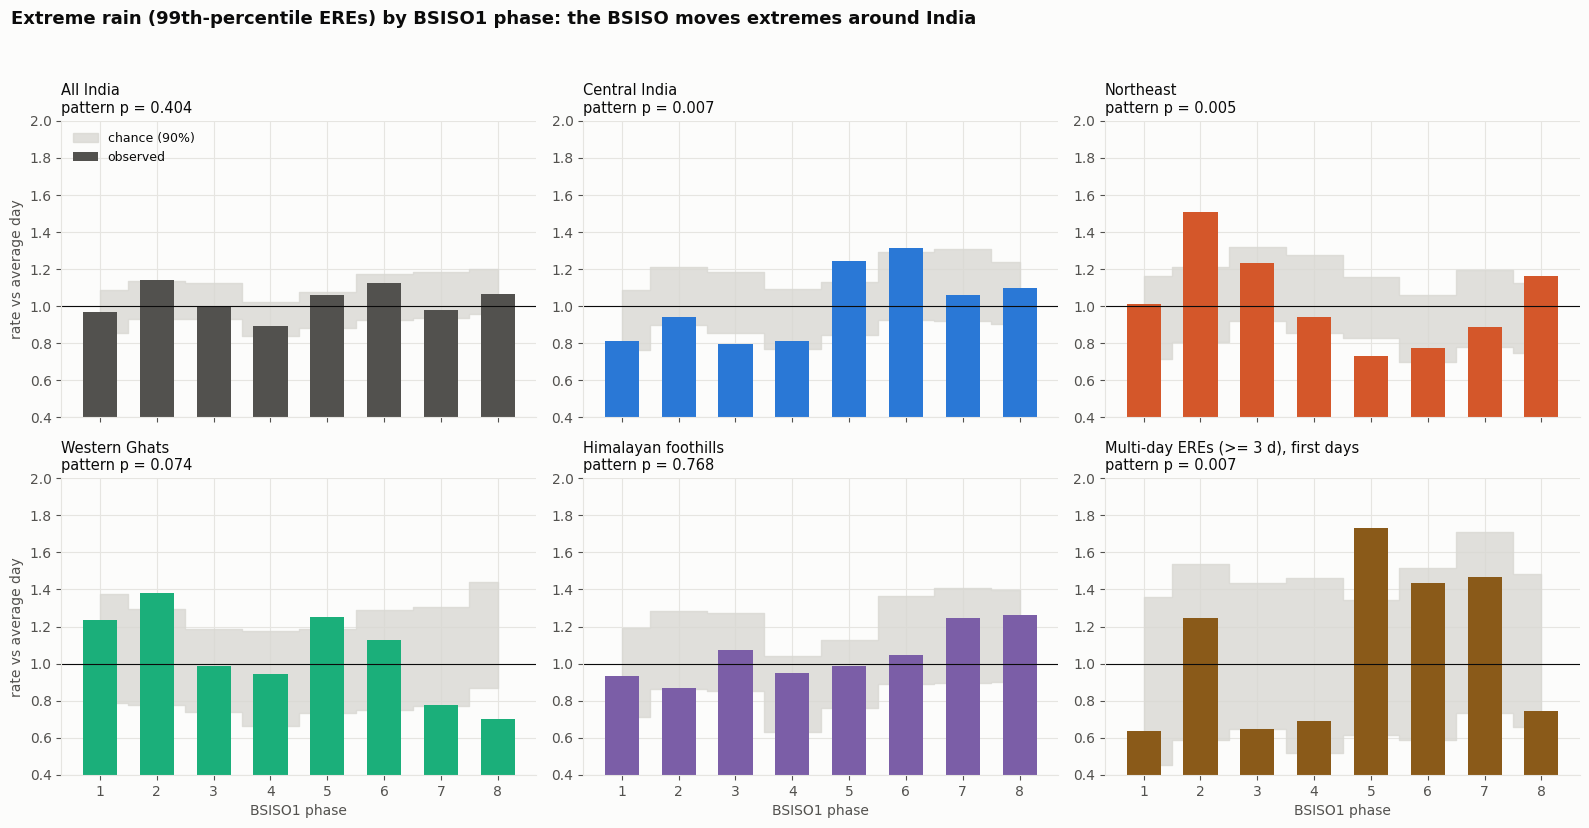

In [18]:
O = pd.read_parquet(find("objdays_enriched.parquet"))           # one row per ERE object per day (MIN-0.05 catalogue)
T = pd.read_parquet(find("tracks_enriched.parquet"))            # one row per ERE track
O["date"] = pd.to_datetime(O["date"].astype(str))
T["birth"] = pd.to_datetime(T["birth_date"].astype(str))
assert len(O) == 10877 and len(T) == 10006, "expected the MIN-0.05 ERE catalogue"

REG = {"central_india": ("Central India", BLUE), "northeast": ("Northeast", "#d4572a"),
       "west_ghats": ("Western Ghats", GREEN), "himalayan_foothills": ("Himalayan foothills", "#7b5ea7"),
       "other": ("Other", "#8f8e89")}
M1 = MODES["BSISO1"]
PH = np.where(M1["amp"] >= 1, M1["phase"], 0)                   # 0 = BSISO inactive (amplitude < 1)

# daily series on the IMERG days: ERE object-days per region, and first days of multi-day (>= 3 d) EREs
cnt = O.groupby(["date", "region"]).size().unstack(fill_value=0).reindex(times, fill_value=0)
SER = {"All India": cnt.sum(axis=1).values.astype(float)}
for r in ("central_india", "northeast", "west_ghats", "himalayan_foothills"):
    SER[REG[r][0]] = cnt[r].values.astype(float)
MULTI = T[T["duration"] >= 3].copy()
SER["Multi-day EREs (>= 3 d), first days"] = MULTI.groupby("birth").size().reindex(times, fill_value=0).values.astype(float)

NPERM = 1000
rng = np.random.default_rng(12)
PERMS = [rng.permutation(NYR) for _ in range(NPERM)]


def phase_ratio(v, ph):
    return np.array([v[ph == k].mean() for k in range(1, 9)]) / v.mean()


rows, RAT = [], {}
for name, v in SER.items():
    obs = phase_ratio(v, PH)
    nul = np.array([phase_ratio(v, PH.reshape(NYR, ND)[p].ravel()) for p in PERMS])   # each summer gets another summer's BSISO
    stat = lambda r: np.abs(r - 1).sum(axis=-1)
    p = (1 + (stat(nul) >= stat(obs)).sum()) / (NPERM + 1)
    RAT[name] = (obs, np.percentile(nul, 5, axis=0), np.percentile(nul, 95, axis=0), p)
    rows.append({"series": name, "events": int(v.sum()), **{f"ph{k}": round(obs[k - 1], 2) for k in range(1, 9)},
                 "pattern p": round(p, 3)})
print("ERE rate in each BSISO1 phase (amplitude >= 1) relative to the average day; 1.00 = average")
display(pd.DataFrame(rows).set_index("series"))

fig, ax = plt.subplots(2, 3, figsize=(16, 8.4), sharex=True)
x8 = np.arange(1, 9)
cols = [INK2, BLUE, REG["northeast"][1], GREEN, REG["himalayan_foothills"][1], BROWN]
for a, (name, (obs, lo, hi, p)), c in zip(ax.ravel(), RAT.items(), cols):
    a.fill_between(x8, lo, hi, step="mid", color=NULLC, alpha=0.8, label="chance (90%)")
    a.bar(x8, obs, color=c, width=0.6, label="observed")
    a.axhline(1, color=INK, lw=0.8)
    a.set(xticks=x8, ylim=(0.4, 2.0))
    a.set_title(f"{name}\npattern p = {p:.3f}", loc="left", fontsize=10.5)
for a in ax[1]:
    a.set_xlabel("BSISO1 phase")
for a in ax[:, 0]:
    a.set_ylabel("rate vs average day")
ax[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Extreme rain (99th-percentile EREs) by BSISO1 phase: the BSISO moves extremes around India",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(os.path.join(OUT, "fig14_ere_by_phase.png"), dpi=140, bbox_inches="tight")
plt.show()

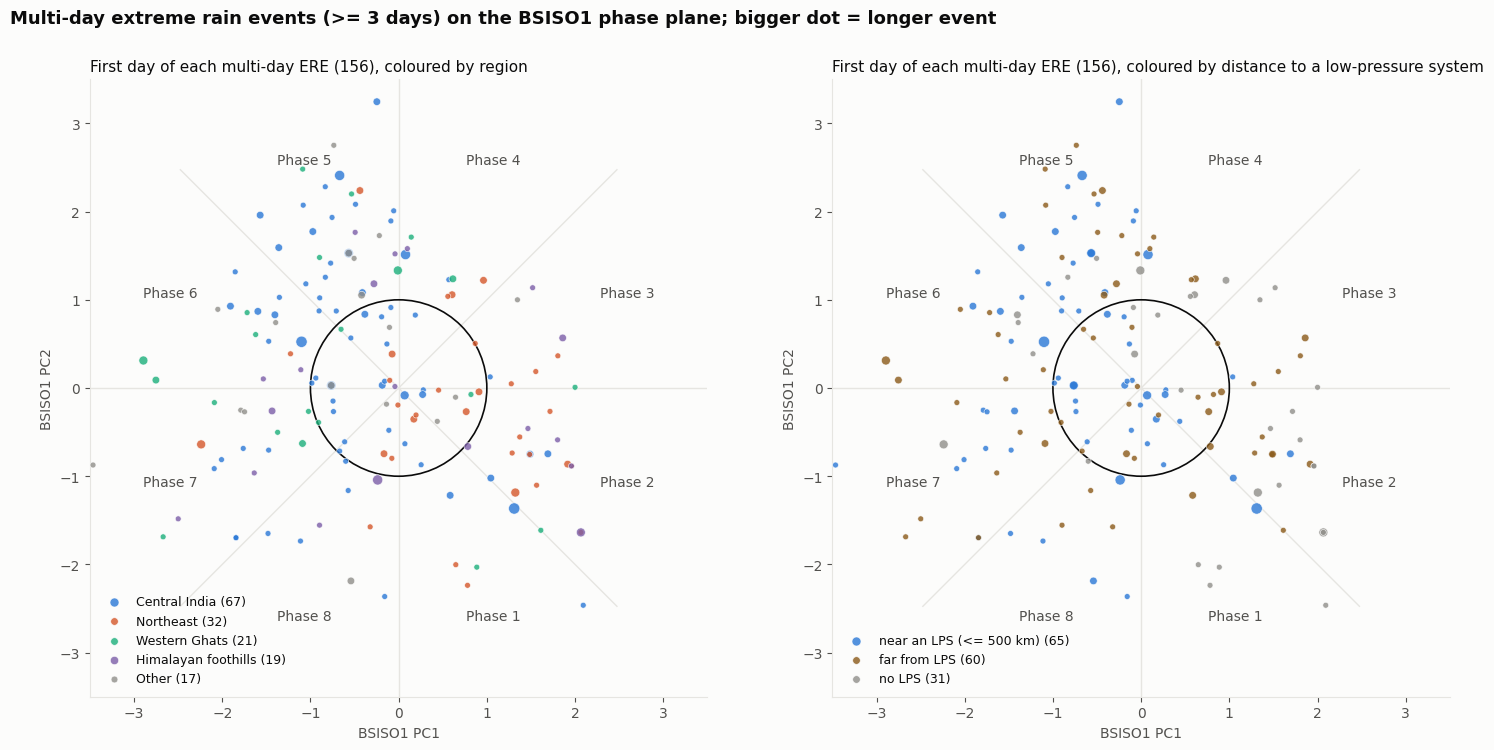

Multi-day EREs by region and BSISO1 phase on their first day


,inactive,ph1,ph2,ph3,ph4,ph5,ph6,ph7,ph8
birth_region,,,,,,,,,
Central India,21,3,3,1,2,18,8,6,5
Himalayan foothills,1,0,5,2,1,3,2,3,2
Northeast,10,2,9,4,3,1,1,1,1
Other,5,0,0,1,0,5,2,3,1
Western Ghats,3,2,0,1,2,4,4,5,0


In [19]:
tix = pd.Series(np.arange(len(times)), index=times)
MULTI = MULTI[MULTI["birth"].isin(tix.index)].copy()
k_ = tix[MULTI["birth"]].values
MULTI["pc1"], MULTI["pc2"], MULTI["phase"] = M1["pc1"][k_], M1["pc2"][k_], PH[k_]

fig, ax = plt.subplots(1, 2, figsize=(15, 7.4))
LPSC = {"near": ("near an LPS (<= 500 km)", BLUE), "far": ("far from LPS", BROWN), "no_lps": ("no LPS", "#8f8e89")}
for a, (key, legend, title) in zip(ax, (("birth_region", REG, "coloured by region"),
                                         ("lps_class", LPSC, "coloured by distance to a low-pressure system"))):
    phase_frame(a, label="Phase ", rmax=3.5, fs=10)
    for kk, (lbl, c) in legend.items():
        s = MULTI[MULTI[key] == kk]
        a.scatter(s["pc1"], s["pc2"], s=18 + 12 * (s["duration"] - 3), color=c, alpha=0.8, ec="white", lw=0.5,
                  zorder=4, label=f"{lbl} ({len(s)})")
    a.set(xlabel="BSISO1 PC1", ylabel="BSISO1 PC2")
    a.set_title(f"First day of each multi-day ERE ({len(MULTI)}), {title}", loc="left", fontsize=11)
    a.legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Multi-day extreme rain events (>= 3 days) on the BSISO1 phase plane; bigger dot = longer event",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(os.path.join(OUT, "fig15_ere_births_phase_plane.png"), dpi=140, bbox_inches="tight")
plt.show()
tab = pd.crosstab(MULTI["birth_region"].map(lambda r: REG[r][0]), MULTI["phase"]).reindex(columns=range(9), fill_value=0)
tab.columns = ["inactive"] + [f"ph{k}" for k in range(1, 9)]
print("Multi-day EREs by region and BSISO1 phase on their first day")
display(tab)

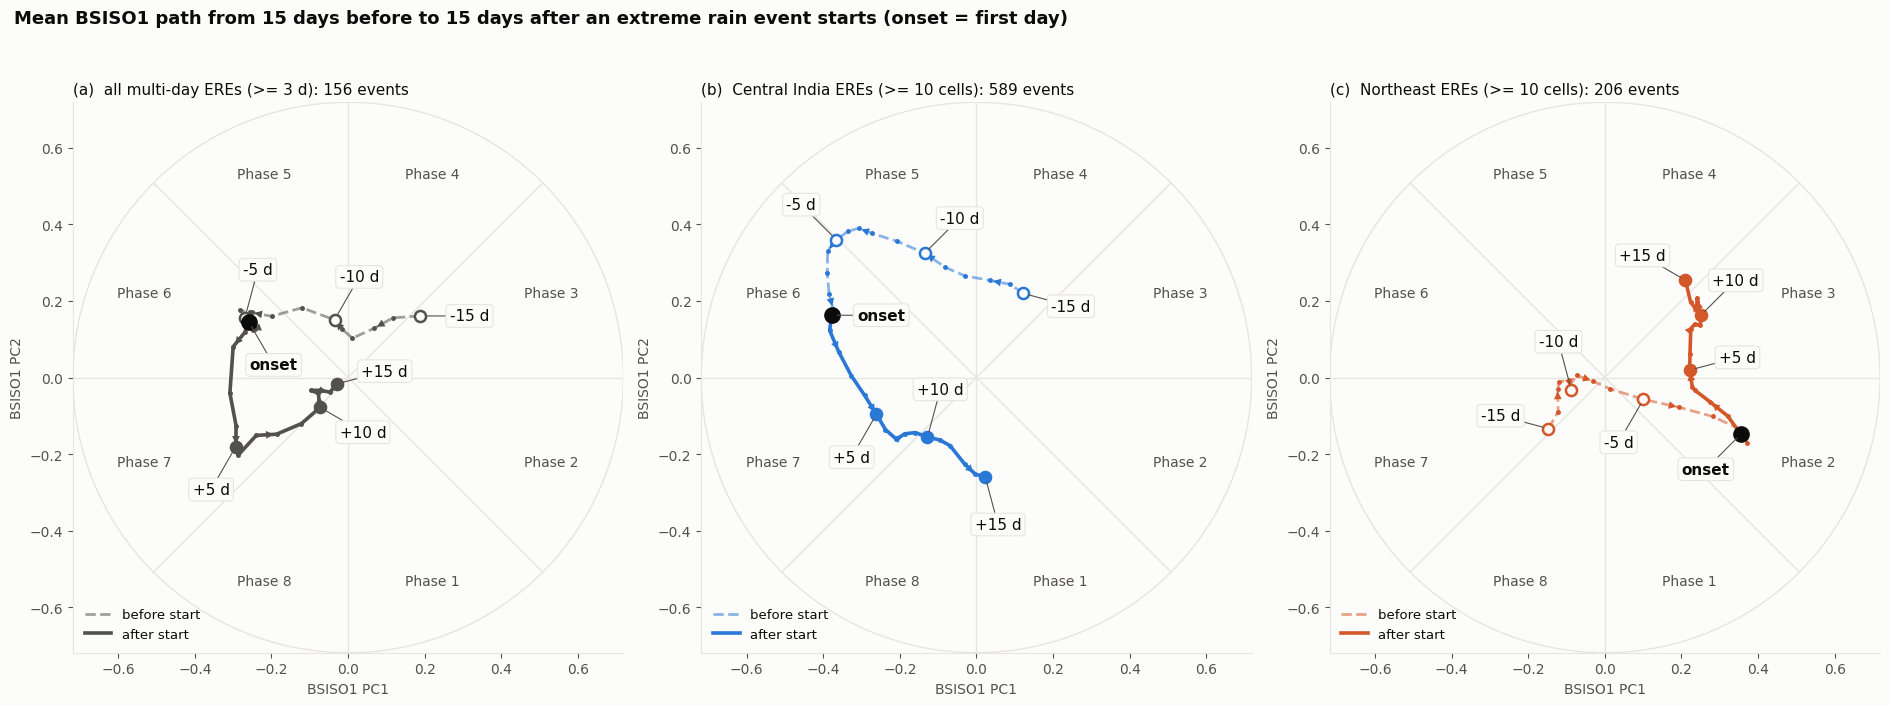

In [20]:
def mean_path_dates(dates):
    mp = np.array([[P1.get(t + pd.Timedelta(days=int(L)), np.nan) for t in dates] for L in LAGS])
    mq = np.array([[P2.get(t + pd.Timedelta(days=int(L)), np.nan) for t in dates] for L in LAGS])
    return np.nanmean(mp, axis=1), np.nanmean(mq, axis=1)


BIG = T[T["peak_size"] >= 10]                                   # EREs reaching at least 10 grid cells
SETS = [("all multi-day EREs (>= 3 d)", MULTI["birth"], INK2),
        ("Central India EREs (>= 10 cells)", BIG.loc[BIG["birth_region"] == "central_india", "birth"], BLUE),
        ("Northeast EREs (>= 10 cells)", BIG.loc[BIG["birth_region"] == "northeast", "birth"], REG["northeast"][1])]
CP = [mean_path_dates(list(d)) for _, d, _ in SETS]
rmax_e = max(0.6, 1.4 * max(np.nanmax(np.hypot(x_, y_)) for x_, y_ in CP))

fig, ax = plt.subplots(1, 3, figsize=(19, 6.9))
for a, (name, d, col), (x_, y_), tag in zip(ax, SETS, CP, "abc"):
    phase_frame(a, label="Phase ", rmax=rmax_e, fs=10)
    for p_ in list(a.patches):                                  # drop the amplitude-1 circle (off-scale)
        p_.remove()
    a.add_patch(plt.Circle((0, 0), rmax_e, fill=False, ec=GRID, lw=1))
    pre, post = LAGS <= 0, LAGS >= 0
    a.plot(x_[pre], y_[pre], "--", color=col, lw=2, alpha=0.55, zorder=3, label="before start")
    a.plot(x_[post], y_[post], "-", color=col, lw=2.6, zorder=3, label="after start")
    a.plot(x_, y_, "o", color=col, ms=2.5, zorder=3)
    for k in range(1, len(LAGS) - 1, 3):
        a.annotate("", (x_[k + 1], y_[k + 1]), (x_[k], y_[k]), zorder=4,
                   arrowprops=dict(arrowstyle="-|>", color=col, lw=0, mutation_scale=14))
    for L in KEY:
        k = int(np.where(LAGS == L)[0][0])
        if L == 0:
            a.plot(x_[k], y_[k], "o", color=INK, ms=11, zorder=5)
        else:
            a.plot(x_[k], y_[k], "o", ms=8, zorder=5, mec=col, mew=1.8, mfc=SURF if L < 0 else col)
    place_labels(a, x_, y_, rmax_e)
    a.set(xlabel="BSISO1 PC1", ylabel="BSISO1 PC2")
    a.set_title(f"({tag})  {name}: {len(d)} events", loc="left", fontsize=11)
    a.legend(frameon=False, fontsize=9.5, loc="lower left")
fig.suptitle("Mean BSISO1 path from 15 days before to 15 days after an extreme rain event starts (onset = first day)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(os.path.join(OUT, "fig16_ere_onset_bsiso_path.png"), dpi=140, bbox_inches="tight")
plt.show()

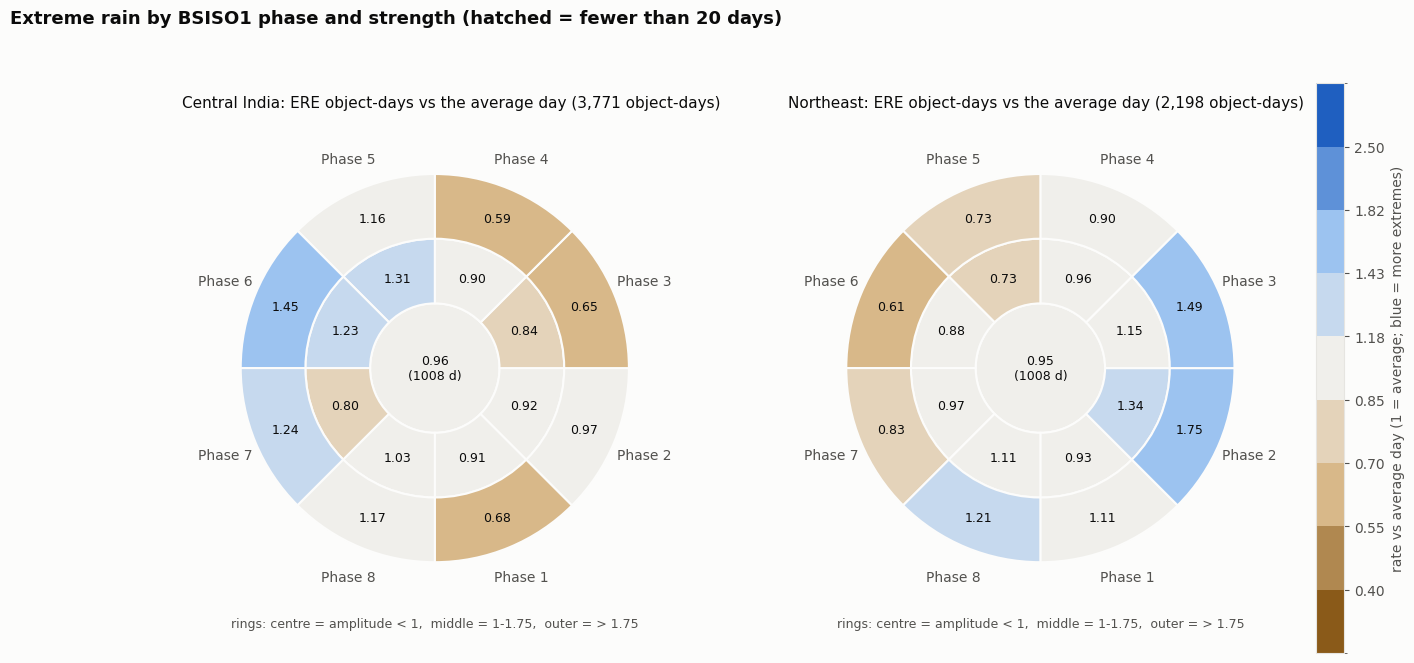

In [21]:
from matplotlib.patches import Wedge
from matplotlib.cm import ScalarMappable

RINGS = [(1.0, 1.75), (1.75, 99)]                              # amplitude bands outside the unit circle
R_DRAW = {(1.0, 1.75): (1, 2), (1.75, 99): (2, 3)}             # where each band is drawn
MIN_DAYS = 20                                                  # leave boxes with too few days blank
RATIO_CM = LinearSegmentedColormap.from_list("ratio", [BROWN, "#d9b98a", NEUT, "#9cc3f0", "#1f5fc0"])
lev = [0.4, 0.55, 0.7, 0.85, 1.18, 1.43, 1.82, 2.5]
norm_r = BoundaryNorm([0] + lev + [99], RATIO_CM.N)
amp1, ph1 = M1["amp"], M1["phase"]

fig, ax = plt.subplots(1, 2, figsize=(15, 7.4))
for a, r in zip(ax, ("central_india", "northeast")):
    v = cnt[r].values.astype(float)
    base = v.mean()
    a.set(xlim=(-3.9, 3.9), ylim=(-3.9, 3.9), aspect="equal")
    a.grid(False)
    a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)
    # inner disk: BSISO inactive (amplitude < 1), phase not meaningful
    s = amp1 < 1
    val = v[s].mean() / base
    a.add_patch(plt.Circle((0, 0), 1, fc=RATIO_CM(norm_r(val)), ec=SURF, lw=1.5))
    a.text(0, 0, f"{val:.2f}\n({s.sum()} d)", ha="center", va="center", fontsize=9, color=INK)
    for k in range(1, 9):
        for band in RINGS:
            s = (ph1 == k) & (amp1 >= band[0]) & (amp1 < band[1])
            r0, r1 = R_DRAW[band]
            # phase k spans angles (k-1)*45 .. k*45 in the to_xy convention; convert to matplotlib degrees
            t0, t1 = (k - 1) * 45 - 90, k * 45 - 90
            if s.sum() < MIN_DAYS:
                a.add_patch(Wedge((0, 0), r1, t0, t1, width=r1 - r0, fc="white", ec=GRID, lw=1, hatch="//"))
                continue
            val = v[s].mean() / base
            a.add_patch(Wedge((0, 0), r1, t0, t1, width=r1 - r0, fc=RATIO_CM(norm_r(val)), ec=SURF, lw=1.5))
            xm, ym = to_xy((k - 0.5) * 45, (r0 + r1) / 2)
            a.text(xm, ym, f"{val:.2f}", ha="center", va="center", fontsize=9, color=INK)
        a.text(*to_xy((k - 0.5) * 45, 3.5), f"Phase {k}", ha="center", va="center", fontsize=10, color=INK2)
    a.text(0, -4.0, "rings: centre = amplitude < 1,  middle = 1-1.75,  outer = > 1.75", ha="center", fontsize=9,
           color=INK2)
    a.set_title(f"{REG[r][0]}: ERE object-days vs the average day ({int(v.sum()):,} object-days)", loc="left",
                fontsize=11)
sm = ScalarMappable(norm=norm_r, cmap=RATIO_CM)
cb = fig.colorbar(sm, ax=ax, fraction=0.025, pad=0.02, ticks=lev)
cb.set_label("rate vs average day (1 = average; blue = more extremes)", color=INK2)
fig.suptitle(f"Extreme rain by BSISO1 phase and strength (hatched = fewer than {MIN_DAYS} days)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.savefig(os.path.join(OUT, "fig17_ere_rate_phase_amplitude.png"), dpi=140, bbox_inches="tight")
plt.show()

rebuilt 10,873 objects; matched 99.7% of the catalogue's object-days
Given an extreme event happens: is it stronger in the BSISO's own phases (boost) and weaker away (suppression)?
boost = in its phases / other phases;  suppression = other phases / BSISO weak (< 1 means suppressed)
medians for event measures, means for track measures; p from 1000 season re-datings (one-sided)


in its phases  other phases  \
region        measure                                                      
Central India peak rain (mm/day)                     94.94         86.28   
              rain / local threshold                  1.11          1.10   
              peak rain, 1-cell events only          79.92         76.87   
              track peak size (cells)                10.86          6.40   
              track duration (days)                   1.14          1.07   
Northeast     peak rain (mm/day)                    104.48         96.25   
              rain / local threshold                  1.12          1.12   
              peak rain, 1-cell events only          87.95         80.93   
              track peak size (cells)                 5.35          3.84   
              track duration (days)                   1.13          1.07   

                                             BSISO weak  boost  boost p  \
region        measure                                                     
Central India peak rain (mm/day)                  90.36  1.100    0.001   
              rain / local threshold               1.11  1.011    0.029   
              peak rain, 1-cell events only       78.26  1.040    0.002   
              track peak size (cells)              7.29  1.697    0.001   
              track duration (days)                1.10  1.066    0.001   
Northeast     peak rain (mm/day)                  97.68  1.086    0.023   
              rain / local threshold               1.12  0.999    0.712   
              peak rain, 1-cell events only       83.29  1.087    0.018   
              track peak size (cells)              4.60  1.396    0.001   
              track duration (days)                1.09  1.061    0.001   

                                             suppression  suppr. p  \
region        measure                                                
Central India peak rain (mm/day)                   0.955     0.001   
              rain / local threshold               0.996     0.168   
              peak rain, 1-cell events only        0.982     0.075   
              track peak size (cells)              0.878     0.063   
              track duration (days)                0.977     0.065   
Northeast     peak rain (mm/day)                   0.985     0.514   
              rain / local threshold               0.996     0.456   
              peak rain, 1-cell events only        0.972     0.242   
              track peak size (cells)              0.833     0.125   
              track duration (days)                0.984     0.355   

                                             boost p (Holm)  
region        measure                                        
Central India peak rain (mm/day)                      0.010  
              rain / local threshold                  0.072  
              peak rain, 1-cell events only           0.010  
              track peak size (cells)                 0.010  
              track duration (days)                   0.010  
Northeast     peak rain (mm/day)                      0.072  
              rain / local threshold                  0.712  
              peak rain, 1-cell events only           0.072  
              track peak size (cells)                 0.010  
              track duration (days)                   0.010

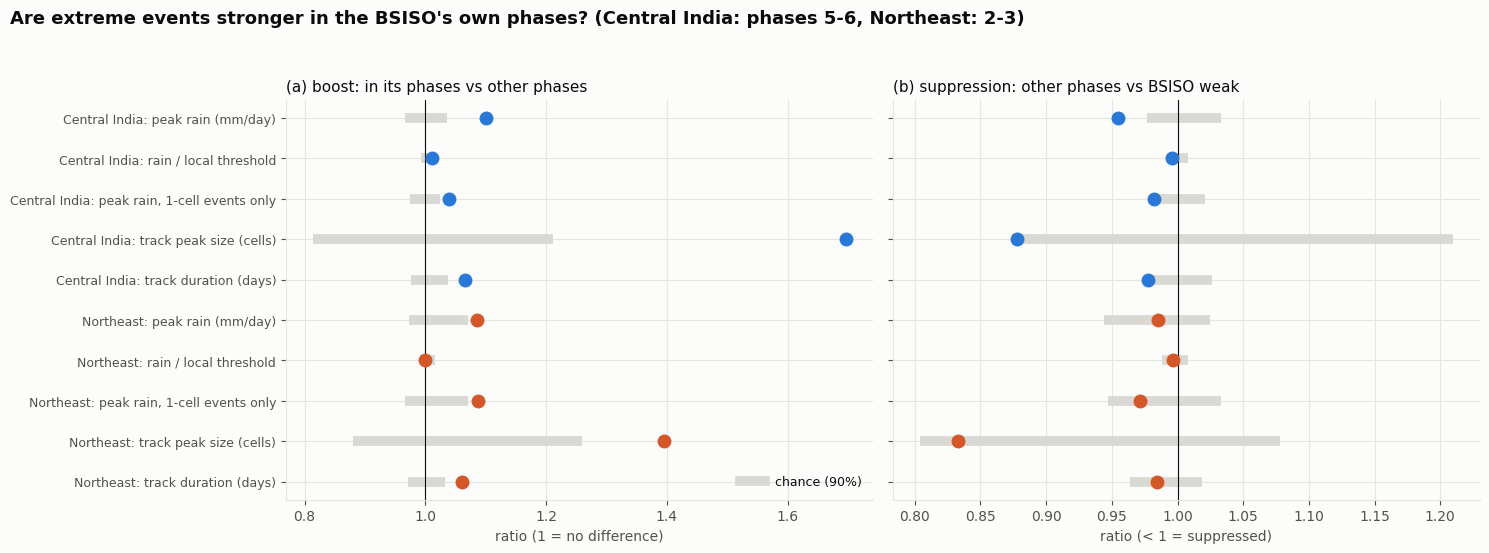

In [22]:
from scipy import ndimage

# Rebuild each ERE object from IMERG to get its rain relative to the LOCAL threshold (location check).
# Same rule as the summer tracker: wet-day (> 1 mm) 99th percentile per grid cell, floored at 50 mm/day,
# India land only, 8-connected cells. Objects are matched to the catalogue by date + centroid.
THR = np.maximum(np.nanpercentile(np.where(tp > 1, tp, np.nan), 99, axis=0), 50).astype("float32")
LA2, LO2 = np.meshgrid(lat, lon, indexing="ij")
parts = []
for t in range(len(times)):
    L, n = ndimage.label(mask & (tp[t] > THR), structure=np.ones((3, 3)))
    if n:
        idx = np.arange(1, n + 1)
        parts.append(pd.DataFrame({"date": times[t], "clat": ndimage.mean(LA2, L, idx), "clon": ndimage.mean(LO2, L, idx),
                                   "rel_int": ndimage.mean(tp[t], L, idx) / ndimage.mean(THR, L, idx)}))
RB = pd.concat(parts, ignore_index=True)
key = lambda d, a, b: d.dt.strftime("%Y%m%d") + "_" + a.round(3).astype(str) + "_" + b.round(3).astype(str)
RB["key"] = key(RB["date"], RB["clat"], RB["clon"])
OI = O.assign(key=key(O["date"], O["centroid_lat"], O["centroid_lon"])).merge(RB[["key", "rel_int"]], on="key", how="left")
print(f"rebuilt {len(RB):,} objects; matched {OI['rel_int'].notna().mean():.1%} of the catalogue's object-days")
OI = OI[OI["date"].isin(tix.index)].copy()
OI["k"] = tix[OI["date"]].values
TI = T[T["birth"].isin(tix.index)].copy()
TI["k"] = tix[TI["birth"]].values
AMP = M1["amp"]
FAV = {"central_india": [5, 6], "northeast": [2, 3]}            # each region's own phases (cell 12)


def remap(k, perm):
    """Same calendar day, but the BSISO taken from another summer (season re-dating null)."""
    y, d = np.divmod(k, ND)
    return perm[y] * ND + d


TESTS = []                                                      # (region, measure, values, day index, summary)
for reg in FAV:
    s = OI[OI["region"] == reg]
    TESTS.append((reg, "peak rain (mm/day)", s["max_mm"].values, s["k"].values, np.median))
    s2 = s.dropna(subset=["rel_int"])
    TESTS.append((reg, "rain / local threshold", s2["rel_int"].values, s2["k"].values, np.median))
    s1 = s[s["size"] == 1]
    TESTS.append((reg, "peak rain, 1-cell events only", s1["max_mm"].values, s1["k"].values, np.median))
    t = TI[TI["birth_region"] == reg]
    TESTS.append((reg, "track peak size (cells)", t["peak_size"].values.astype(float), t["k"].values, np.mean))
    TESTS.append((reg, "track duration (days)", t["duration"].values.astype(float), t["k"].values, np.mean))


def boost_supp(x, k, f, fav):
    ph_, a_ = PH[k], AMP[k]
    in_, away, weak = np.isin(ph_, fav), (ph_ > 0) & ~np.isin(ph_, fav), ph_ == 0
    return f(x[in_]), f(x[away]), f(x[weak])


rows, DOTS = [], []
for reg, name, x, k, f in TESTS:
    fi, fa, fw = boost_supp(x, k, f, FAV[reg])
    nul = np.array([boost_supp(x, remap(k, p), f, FAV[reg]) for p in PERMS])
    b_obs, s_obs = fi / fa, fa / fw
    b_nul, s_nul = nul[:, 0] / nul[:, 1], nul[:, 1] / nul[:, 2]
    rows.append({"region": REG[reg][0], "measure": name, "in its phases": round(fi, 2), "other phases": round(fa, 2),
                 "BSISO weak": round(fw, 2), "boost": round(b_obs, 3),
                 "boost p": (1 + (b_nul >= b_obs).sum()) / (NPERM + 1),
                 "suppression": round(s_obs, 3), "suppr. p": (1 + (s_nul <= s_obs).sum()) / (NPERM + 1)})
    DOTS.append((f"{REG[reg][0]}: {name}", b_obs, np.percentile(b_nul, [5, 95]), s_obs, np.percentile(s_nul, [5, 95]),
                 REG[reg][1]))
IT = pd.DataFrame(rows)
# Holm correction across the 10 boost tests (several measures were tried, so the p-values are adjusted)
order = np.argsort(IT["boost p"].values)
m_ = len(IT)
adj = np.maximum.accumulate([min(1, (m_ - i) * IT["boost p"].values[j]) for i, j in enumerate(order)])
IT.loc[IT.index[order], "boost p (Holm)"] = adj
print("Given an extreme event happens: is it stronger in the BSISO's own phases (boost) and weaker away (suppression)?")
print("boost = in its phases / other phases;  suppression = other phases / BSISO weak (< 1 means suppressed)")
print("medians for event measures, means for track measures; p from 1000 season re-datings (one-sided)")
display(IT.set_index(["region", "measure"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), sharey=True)
yy = np.arange(len(DOTS))[::-1]
for a, (j, ttl, xl) in zip(ax, ((1, "(a) boost: in its phases vs other phases", "ratio (1 = no difference)"),
                                 (3, "(b) suppression: other phases vs BSISO weak", "ratio (< 1 = suppressed)"))):
    for y_, d in zip(yy, DOTS):
        lo, hi = d[j + 1]
        a.plot([lo, hi], [y_, y_], color=NULLC, lw=7, solid_capstyle="butt", zorder=1)
        a.plot(d[j], y_, "o", color=d[5], ms=9, zorder=3)
    a.axvline(1, color=INK, lw=0.8)
    a.set(xlabel=xl)
    a.set_title(ttl, loc="left", fontsize=11)
ax[0].set_yticks(yy, [d[0] for d in DOTS], fontsize=9)
ax[0].plot([], [], color=NULLC, lw=7, label="chance (90%)")
ax[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Are extreme events stronger in the BSISO's own phases? (Central India: phases 5-6, Northeast: 2-3)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(os.path.join(OUT, "fig18_ere_intensity_test.png"), dpi=140, bbox_inches="tight")
plt.show()

How the BSISO effect changes with event size (p from 1000 season re-datings, one-sided)


tracks more in its phases      p  \
region        min size (cells)                                     
Central India 1                   3466              x1.31  0.001   
              4                   1254              x1.51  0.001   
              8                    705              x1.86  0.001   
              16                   405              x2.14  0.001   
              30                   213              x2.61  0.001   
Northeast     1                   2011              x1.44  0.004   
              4                    579              x1.87  0.001   
              8                    273              x2.18  0.001   
              16                   110              x2.36  0.009   
              30                    36              x4.87  0.001   

                               fewer away (vs weak BSISO)     p   \
region        min size (cells)                                     
Central India 1                                     x0.96  0.053   
              4                                     x0.85  0.004   
              8                                     x0.77  0.002   
              16                                    x0.69  0.001   
              30                                    x0.75  0.024   
Northeast     1                                     x0.96  0.557   
              4                                     x0.82  0.198   
              8                                     x0.99  0.782   
              16                                    x0.75  0.350   
              30                                    x0.38  0.023   

                               rain / local threshold    p    
region        min size (cells)                                
Central India 1                                x1.011  0.029  
              4                                x1.012  0.098  
              8                                x0.999  0.579  
              16                               x1.016  0.195  
              30                               x1.021  0.265  
Northeast     1                                x0.999  0.712  
              4                                x0.987  0.877  
              8                                x1.004  0.437  
              16                               x1.011  0.464  
              30                               x0.925  0.914

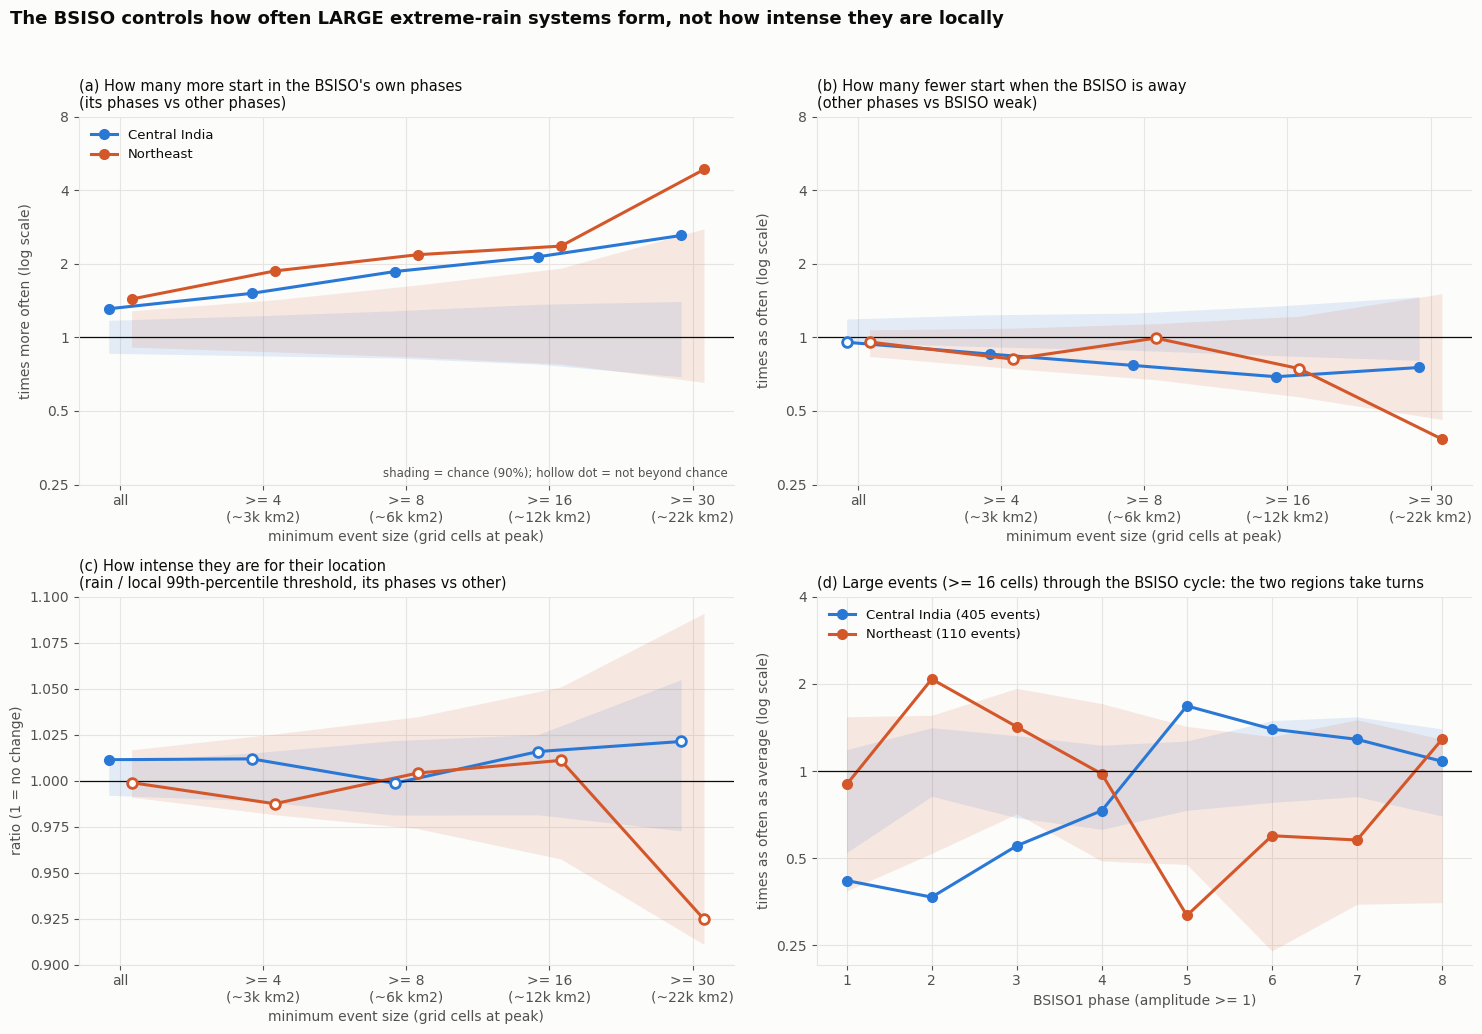

In [23]:
SIZES = [1, 4, 8, 16, 30]                                       # minimum peak size of a track (grid cells; 1 cell ~ 750 km2)
BIG_S = 16                                                      # size used for the phase-cycle panel
PHR = PH.reshape(NYR, ND)


def births_per_day(reg, s_min):
    tb = TI[(TI["birth_region"] == reg) & (TI["peak_size"] >= s_min)]
    return np.bincount(tb["k"].values, minlength=len(times)).astype(float), len(tb)


def freq_ratios(v, ph_arr, fav):
    f = np.isin(ph_arr, fav)
    u, w = (ph_arr > 0) & ~f, ph_arr == 0
    return v[f].mean() / v[u].mean(), v[u].mean() / v[w].mean()


def rel_ratio(x, k, fav):
    f = np.isin(PH[k], fav)
    u = (PH[k] > 0) & ~f
    return np.median(x[f]) / np.median(x[u])


RES = {}
for reg, fav in FAV.items():
    out = {"boost": [], "supp": [], "int": [], "n": []}
    for s_min in SIZES:
        v, n = births_per_day(reg, s_min)
        obs = freq_ratios(v, PH, fav)
        nul = np.array([freq_ratios(v, PHR[p].ravel(), fav) for p in PERMS])
        out["boost"].append((obs[0], *np.percentile(nul[:, 0], [5, 95]), (1 + (nul[:, 0] >= obs[0]).sum()) / (NPERM + 1)))
        out["supp"].append((obs[1], *np.percentile(nul[:, 1], [5, 95]), (1 + (nul[:, 1] <= obs[1]).sum()) / (NPERM + 1)))
        s = OI[(OI["region"] == reg) & (OI["size"] >= s_min)].dropna(subset=["rel_int"])
        x, k = s["rel_int"].values, s["k"].values
        io = rel_ratio(x, k, fav)
        inul = np.array([rel_ratio(x, remap(k, p), fav) for p in PERMS])
        out["int"].append((io, *np.percentile(inul, [5, 95]), (1 + (inul >= io).sum()) / (NPERM + 1)))
        out["n"].append(n)
    RES[reg] = {key: np.array(val) for key, val in out.items()}

rows = []
for reg in FAV:
    for i, s_min in enumerate(SIZES):
        b, sp, it = RES[reg]["boost"][i], RES[reg]["supp"][i], RES[reg]["int"][i]
        rows.append({"region": REG[reg][0], "min size (cells)": s_min, "tracks": int(RES[reg]["n"][i]),
                     "more in its phases": f"x{b[0]:.2f}", "p": round(b[3], 3),
                     "fewer away (vs weak BSISO)": f"x{sp[0]:.2f}", "p ": round(sp[3], 3),
                     "rain / local threshold": f"x{it[0]:.3f}", "p  ": round(it[3], 3)})
print("How the BSISO effect changes with event size (p from 1000 season re-datings, one-sided)")
display(pd.DataFrame(rows).set_index(["region", "min size (cells)"]))

fig, ax = plt.subplots(2, 2, figsize=(15, 10.5))
xs = np.arange(len(SIZES))
off = {"central_india": -0.08, "northeast": 0.08}
panels = (("boost", ax[0, 0], "(a) How many more start in the BSISO's own phases\n(its phases vs other phases)",
           "times more often (log scale)"),
          ("supp", ax[0, 1], "(b) How many fewer start when the BSISO is away\n(other phases vs BSISO weak)",
           "times as often (log scale)"),
          ("int", ax[1, 0], "(c) How intense they are for their location\n(rain / local 99th-percentile threshold, its phases vs other)",
           "ratio (1 = no change)"))
for key, a, ttl, yl in panels:
    for reg in FAV:
        r = RES[reg][key]
        c = REG[reg][1]
        a.fill_between(xs + off[reg], r[:, 1], r[:, 2], color=c, alpha=0.12, lw=0)
        a.plot(xs + off[reg], r[:, 0], "o-", color=c, lw=2.2, ms=7, label=REG[reg][0])
        for i in range(len(SIZES)):                              # filled = beats chance (p < 0.05), hollow = not
            if r[i, 3] >= 0.05:
                a.plot(xs[i] + off[reg], r[i, 0], "o", ms=7, mfc=SURF, mec=c, mew=2, zorder=4)
    a.axhline(1, color=INK, lw=0.9)
    a.set_xticks(xs, [f">= {s}\n(~{s * 750 / 1000:.0f}k km2)" if s > 1 else "all" for s in SIZES])
    a.set(xlabel="minimum event size (grid cells at peak)", ylabel=yl)
    a.set_title(ttl, loc="left", fontsize=10.5)
for a in (ax[0, 0], ax[0, 1]):
    a.set_yscale("log")
    a.set_yticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
    a.minorticks_off()
ax[1, 0].set_ylim(0.9, 1.1)
ax[0, 0].legend(frameon=False, fontsize=9.5, loc="upper left")
ax[0, 0].text(0.99, 0.02, "shading = chance (90%); hollow dot = not beyond chance", transform=ax[0, 0].transAxes,
              ha="right", fontsize=8.5, color=INK2)
# (d) large events through the BSISO cycle: Central India and the Northeast take turns
a = ax[1, 1]
x8 = np.arange(1, 9)
for reg in FAV:
    v, n = births_per_day(reg, BIG_S)
    obs = np.array([v[PH == k].mean() for k in x8]) / v.mean()
    nul = np.array([[v[PHR[p].ravel() == k].mean() for k in x8] for p in PERMS]) / v.mean()
    c = REG[reg][1]
    a.fill_between(x8, *np.percentile(nul, [5, 95], axis=0), color=c, alpha=0.12, lw=0)
    a.plot(x8, obs, "o-", color=c, lw=2.2, ms=7, label=f"{REG[reg][0]} ({n} events)")
a.axhline(1, color=INK, lw=0.9)
a.set_yscale("log")
a.set_yticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
a.minorticks_off()
a.set(xticks=x8, xlabel="BSISO1 phase (amplitude >= 1)", ylabel="times as often as average (log scale)")
a.set_title(f"(d) Large events (>= {BIG_S} cells) through the BSISO cycle: the two regions take turns", loc="left",
            fontsize=10.5)
a.legend(frameon=False, fontsize=9.5, loc="upper left")
fig.suptitle("The BSISO controls how often LARGE extreme-rain systems form, not how intense they are locally",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(os.path.join(OUT, "fig19_ere_size_selectivity.png"), dpi=140, bbox_inches="tight")
plt.show()